## Road Accident Analysis Using Data Science and Machine Learning

## Project Description
- Road accidents are a major concern that can result in injuries, loss of life, and damage to property. Analyzing historical accident data can help identify patterns and factors associated with road accidents and their severity. This project focuses on analyzing road accident data using Data Science and Machine Learning techniques to understand accident patterns and identify factors associated with accident severity. Exploratory Data Analysis and data visualization will be used to discover meaningful relationships in the dataset, followed by machine-learning techniques to predict accident severity based on relevant accident-related features.
## Objectives
- To analyze road accident patterns and trends.
- To identify factors affecting accident severity.
- To perform EDA and data visualization.
- To identify important features related to accident severity.
- To develop a machine-learning model for accident severity prediction.
- To derive useful insights for improving road safety
## Features


In [ ]:
# importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [ ]:

# Load the datset
from google.colab import files
uploaded = files.upload()

Saving Road Accident Data.xlsx to Road Accident Data.xlsx


In [ ]:
import io
df=pd.read_excel(io.BytesIO(uploaded["Road Accident Data.xlsx"]))
df

,Accident_Index,Accident Date,Day_of_Week,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,Local_Authority_(District),Carriageway_Hazards,...,Number_of_Casualties,Number_of_Vehicles,Police_Force,Road_Surface_Conditions,Road_Type,Speed_limit,Time,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
0,200901BS70001,2021-01-01,Thursday,Give way or uncontrolled,T or staggered junction,Serious,51.512273,Daylight,Kensington and Chelsea,NaN,...,1,2,Metropolitan Police,Dry,One way street,30,15:11:00,Urban,Fine no high winds,Car
1,200901BS70002,2021-01-05,Monday,Give way or uncontrolled,Crossroads,Serious,51.514399,Daylight,Kensington and Chelsea,NaN,...,11,2,Metropolitan Police,Wet or damp,Single carriageway,30,10:59:00,Urban,Fine no high winds,Taxi/Private hire car
2,200901BS70003,2021-01-04,Sunday,Give way or uncontrolled,T or staggered junction,Slight,51.486668,Daylight,Kensington and Chelsea,NaN,...,1,2,Metropolitan Police,Dry,Single carriageway,30,14:19:00,Urban,Fine no high winds,Taxi/Private hire car
3,200901BS70004,2021-01-05,Monday,Auto traffic signal,T or staggered junction,Serious,51.507804,Daylight,Kensington and Chelsea,NaN,...,1,2,Metropolitan Police,Frost or ice,Single carriageway,30,08:10:00,Urban,Other,Motorcycle over 500cc
4,200901BS70005,2021-01-06,Tuesday,Auto traffic signal,Crossroads,Serious,51.482076,Darkness - lights lit,Kensington and Chelsea,NaN,...,1,2,Metropolitan Police,Dry,Single carriageway,30,17:25:00,Urban,Fine no high winds,Car
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307968,201091NM01760,2022-02-18,Thursday,Data missing or out of range,Not at junction or within 20 metres,Slight,57.374005,Daylight,Highland,NaN,...,2,1,Northern,Dry,Single carriageway,60,07:00:00,Rural,Fine no high winds,Car
307969,201091NM01881,2022-02-21,Sunday,Data missing or out of range,Not at junction or within 20 metres,Slight,57.232273,Darkness - no lighting,Highland,NaN,...,1,1,Northern,Frost or ice,Single carriageway,60,03:00:00,Rural,Fine no high winds,Car
307970,201091NM01935,2022-02-23,Tuesday,Give way or uncontrolled,T or staggered junction,Slight,57.585044,Daylight,Highland,NaN,...,1,3,Northern,Frost or ice,Single carriageway,30,09:38:00,Rural,Fine no high winds,Car
307971,201091NM01964,2022-02-23,Tuesday,Give way or uncontrolled,T or staggered junction,Serious,57.214898,Darkness - no lighting,Highland,NaN,...,1,2,Northern,Wet or damp,Single carriageway,60,18:25:00,Rural,Fine no high winds,Motorcycle over 500cc


# Basic Information and Data Cleaning


In [ ]:
df[["Accident Date","Day_of_Week","Accident_Severity","Local_Authority_(District)",
    "Speed_limit","Road_Type","Weather_Conditions","Light_Conditions",
    "Urban_or_Rural_Area","Vehicle_Type"]].sample(5, random_state=42)

,Accident Date,Day_of_Week,Accident_Severity,Local_Authority_(District),Speed_limit,Road_Type,Weather_Conditions,Light_Conditions,Urban_or_Rural_Area,Vehicle_Type
150629,2021-05-15,Saturday,Slight,Carmarthenshire,30,Single carriageway,Fine no high winds,Daylight,Urban,Car
279926,2022-10-27,Thursday,Slight,Medway,30,Single carriageway,Fine no high winds,Darkness - lights lit,Urban,Car
124330,2021-05-29,Saturday,Slight,Canterbury,30,Single carriageway,Fine no high winds,Daylight,Urban,Car
103354,2021-02-06,Saturday,Slight,Southend-on-Sea,30,Single carriageway,Fine no high winds,Daylight,Urban,Car
117419,2021-12-02,Thursday,Slight,Southampton,30,Single carriageway,Fine no high winds,Daylight,Urban,Car


In [ ]:
df.sample(3, random_state=42).T

,150629,279926,124330
Accident_Index,200963AC15509,2010000000000,2010000000000
Accident Date,2021-05-15 00:00:00,2022-10-27 00:00:00,2021-05-29 00:00:00
Day_of_Week,Saturday,Thursday,Saturday
Junction_Control,Data missing or out of range,Give way or uncontrolled,Give way or uncontrolled
Junction_Detail,Not at junction or within 20 metres,T or staggered junction,Crossroads
Accident_Severity,Slight,Slight,Slight
Latitude,51.672884,51.367151,51.371392
Light_Conditions,Daylight,Darkness - lights lit,Daylight
Local_Authority_(District),Carmarthenshire,Medway,Canterbury
Carriageway_Hazards,Unknown,Unknown,Unknown


In [ ]:
df.sample()

,Accident_Index,Accident Date,Day_of_Week,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,Local_Authority_(District),Carriageway_Hazards,...,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type,Month,Year,Day_Type,Latitude_Range,Longitude_Range,Casualty_Range,Hour
285483,2010000000000,2022-04-28,Thursday,Give way or uncontrolled,Roundabout,Slight,50.841767,Daylight,Chichester,Unknown,...,Rural,Fine no high winds,Car,April,2022,Weekday,49.9–51,-2 to 0,1,17


In [ ]:
df.sample(5)

,Accident_Index,Accident Date,Day_of_Week,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,Local_Authority_(District),Carriageway_Hazards,...,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type,Month,Year,Day_Type,Latitude_Range,Longitude_Range,Casualty_Range,Hour
64433,200920D122002,2021-03-16,Tuesday,Give way or uncontrolled,T or staggered junction,Slight,52.534625,Daylight,Birmingham,Unknown,...,Urban,Fine no high winds,Car,March,2021,Weekday,52–53,-2 to 0,2,14
199220,201006K028066,2022-02-17,Thursday,Give way or uncontrolled,Crossroads,Serious,53.566245,Darkness - lights lit,Bolton,Unknown,...,Urban,Fine no high winds,Car,February,2022,Weekday,53–54,-4 to -2,4,19
110135,200943P328129,2021-12-27,Monday,Give way or uncontrolled,Roundabout,Slight,51.740350,Daylight,South Oxfordshire,Unknown,...,Rural,Fine no high winds,Goods 7.5 tonnes mgw and over,December,2021,Weekday,51–52,-2 to 0,1,14
145953,2010000000000,2021-07-24,Saturday,Give way or uncontrolled,Other junction,Slight,53.236760,Daylight,Flintshire,Any animal in carriageway (except ridden horse),...,Urban,Raining no high winds,Goods 7.5 tonnes mgw and over,July,2021,Weekend,53–54,-4 to -2,2,15
30396,200905BB30514,2021-01-29,Friday,Auto traffic signal,Other junction,Slight,53.450064,Daylight,Sefton,Unknown,...,Urban,Fine no high winds,Car,January,2021,Weekday,53–54,-4 to -2,1,17


In [ ]:
df.tail()

,Accident_Index,Accident Date,Day_of_Week,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,Local_Authority_(District),Carriageway_Hazards,...,Number_of_Casualties,Number_of_Vehicles,Police_Force,Road_Surface_Conditions,Road_Type,Speed_limit,Time,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
307968,201091NM01760,2022-02-18,Thursday,Data missing or out of range,Not at junction or within 20 metres,Slight,57.374005,Daylight,Highland,NaN,...,2,1,Northern,Dry,Single carriageway,60,07:00:00,Rural,Fine no high winds,Car
307969,201091NM01881,2022-02-21,Sunday,Data missing or out of range,Not at junction or within 20 metres,Slight,57.232273,Darkness - no lighting,Highland,NaN,...,1,1,Northern,Frost or ice,Single carriageway,60,03:00:00,Rural,Fine no high winds,Car
307970,201091NM01935,2022-02-23,Tuesday,Give way or uncontrolled,T or staggered junction,Slight,57.585044,Daylight,Highland,NaN,...,1,3,Northern,Frost or ice,Single carriageway,30,09:38:00,Rural,Fine no high winds,Car
307971,201091NM01964,2022-02-23,Tuesday,Give way or uncontrolled,T or staggered junction,Serious,57.214898,Darkness - no lighting,Highland,NaN,...,1,2,Northern,Wet or damp,Single carriageway,60,18:25:00,Rural,Fine no high winds,Motorcycle over 500cc
307972,201091NM02142,2022-02-28,Sunday,Give way or uncontrolled,T or staggered junction,Serious,57.575210,Daylight,Highland,Other object on road,...,1,1,Northern,Wet or damp,Dual carriageway,60,15:45:00,Rural,Snowing no high winds,Car


In [ ]:
# shape of Data before cleaning.
df.shape

(307973, 21)

In [ ]:
df.columns

Index(['Accident_Index', 'Accident Date', 'Day_of_Week', 'Junction_Control',
       'Junction_Detail', 'Accident_Severity', 'Latitude', 'Light_Conditions',
       'Local_Authority_(District)', 'Carriageway_Hazards', 'Longitude',
       'Number_of_Casualties', 'Number_of_Vehicles', 'Police_Force',
       'Road_Surface_Conditions', 'Road_Type', 'Speed_limit', 'Time',
       'Urban_or_Rural_Area', 'Weather_Conditions', 'Vehicle_Type'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307973 entries, 0 to 307972
Data columns (total 21 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   Accident_Index              307973 non-null  object        
 1   Accident Date               307973 non-null  datetime64[ns]
 2   Day_of_Week                 307973 non-null  object        
 3   Junction_Control            307973 non-null  object        
 4   Junction_Detail             307973 non-null  object        
 5   Accident_Severity           307973 non-null  object        
 6   Latitude                    307973 non-null  float64       
 7   Light_Conditions            307973 non-null  object        
 8   Local_Authority_(District)  307973 non-null  object        
 9   Carriageway_Hazards         5424 non-null    object        
 10  Longitude                   307973 non-null  float64       
 11  Number_of_Casualties        307973 non-

In [ ]:
df.describe()

,Accident Date,Latitude,Longitude,Number_of_Casualties,Number_of_Vehicles,Speed_limit
count,307973,307973.000000,307973.000000,307973.000000,307973.000000,307973.000000
mean,2021-12-23 22:19:39.804722944,52.487005,-1.368884,1.356882,1.829063,38.866037
min,2021-01-01 00:00:00,49.914488,-7.516225,1.000000,1.000000,10.000000
25%,2021-06-28 00:00:00,51.485248,-2.247937,1.000000,1.000000,30.000000
50%,2021-12-08 00:00:00,52.225943,-1.349258,1.000000,2.000000,30.000000
75%,2022-06-25 00:00:00,53.415517,-0.206810,1.000000,2.000000,50.000000
max,2022-12-31 00:00:00,60.598055,1.759398,48.000000,32.000000,70.000000
std,NaN,1.339011,1.356092,0.815857,0.710477,14.032933


In [ ]:
df.isnull().sum()

,0
Accident_Index,0
Accident Date,0
Day_of_Week,0
Junction_Control,0
Junction_Detail,0
Accident_Severity,0
Latitude,0
Light_Conditions,0
Local_Authority_(District),0
Carriageway_Hazards,302549


In [ ]:
df = df.dropna(subset=['Time'])

In [ ]:
cols = [
    'Carriageway_Hazards',
    'Road_Surface_Conditions',
    'Road_Type',
    'Weather_Conditions'
]

for col in cols:
    df[col] = df[col].fillna('Unknown')

/tmp/ipykernel_1397/3470983179.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df[col] = df[col].fillna('Unknown')


In [ ]:
df.isnull().sum()

,0
Accident_Index,0
Accident Date,0
Day_of_Week,0
Junction_Control,0
Junction_Detail,0
Accident_Severity,0
Latitude,0
Light_Conditions,0
Local_Authority_(District),0
Carriageway_Hazards,0


In [ ]:
df.duplicated().sum()

np.int64(1)

In [ ]:
df=df.drop_duplicates()

In [ ]:
df.dtypes

,0
Accident_Index,object
Accident Date,datetime64[ns]
Day_of_Week,object
Junction_Control,object
Junction_Detail,object
Accident_Severity,object
Latitude,float64
Light_Conditions,object
Local_Authority_(District),object
Carriageway_Hazards,object


- The dataset originally contained 307,973 accident records and 21 columns, providing a large dataset for analysis.
- The dataset contains a mix of categorical, numerical, geographical, date, and time-related features, making it suitable for analysing different factors related to accident severity.
- Most columns had complete data, but Carriageway_Hazards had a very large number of missing values (302,549). Smaller amounts of missing data were also present in Weather_Conditions, Road_Type, Road_Surface_Conditions, and Time.
- The missing values were handled by removing the 17 records with missing Time values and replacing missing values in selected categorical columns with "Unknown", resulting in no remaining missing values.
- The numerical variables show reasonable variation: accidents involved 1 to 48 casualties, 1 to 32 vehicles, and occurred on roads with speed limits ranging from 10 to 70 mph.

## Univarient Analysis


In [ ]:
df["Accident_Index"].nunique()

197644

In [ ]:
# Shape of Dataset after cleaning
df.shape[0]

307955

In [ ]:
df["Accident_Index"].duplicated().sum()

np.int64(110311)

In [ ]:
print(df['Accident_Index'].dtype)

print(df['Accident_Index'].head())

print(df['Accident_Index'].nunique())

print(df['Accident_Index'].isna().sum())

object
0    200901BS70001
1    200901BS70002
2    200901BS70003
3    200901BS70004
4    200901BS70005
Name: Accident_Index, dtype: object
197644
0



- Accident_Index: This column is used as an identifier for accident records and does not contain analytical information. Therefore, it was excluded from further statistical analysis and visualization. Some records contain repeated/irregular identifier values, but the corresponding accident records contain different information, so the records were retained.

In [ ]:
# Accident date
df['Month'] = df['Accident Date'].dt.month_name()

In [ ]:

df['Month'].value_counts()

,count
Month,
November,29094
October,28368
July,26952
September,26751
June,26747
May,26182
March,25542
August,25501
April,24224


In [ ]:
df['Month'].value_counts().max() # In the month of November most accidents are occur

29094

In [ ]:
df['Month'].value_counts().min()# In the month of February lowest accidents are occur

21882

<Axes: xlabel='Month'>

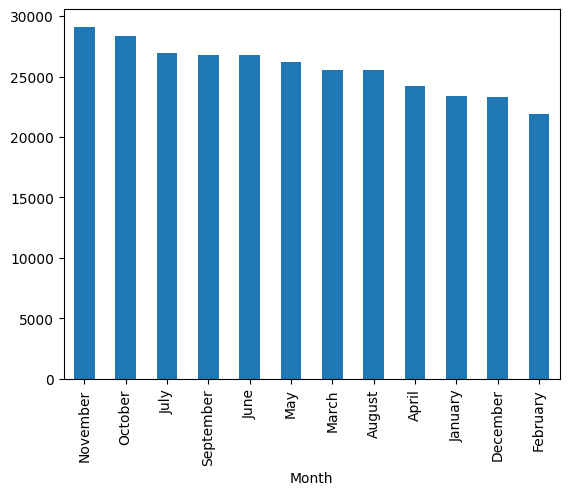

In [ ]:
df['Month'].value_counts().plot(kind="bar")

In [ ]:

df['Year'] = df['Accident Date'].dt.year

In [ ]:
df['Year'].value_counts()

,count
Year,
2021,163536
2022,144419


<Axes: ylabel='count'>

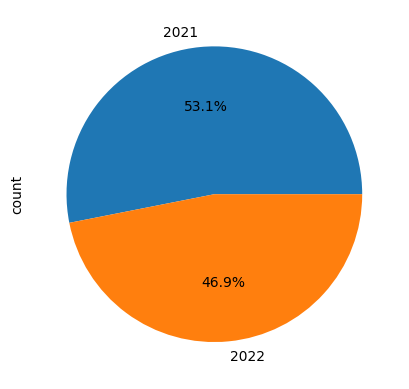

In [ ]:
df['Year'].value_counts().plot(kind="pie",autopct="%1.1f%%")

In [ ]:
df['Day_of_Week'] = df['Accident Date'].dt.day_name()

In [ ]:

df['Day_of_Week'].value_counts()

,count
Day_of_Week,
Saturday,50529
Wednesday,46382
Thursday,46378
Friday,45646
Tuesday,43913
Sunday,41564
Monday,33543


<Axes: xlabel='Day_of_Week'>

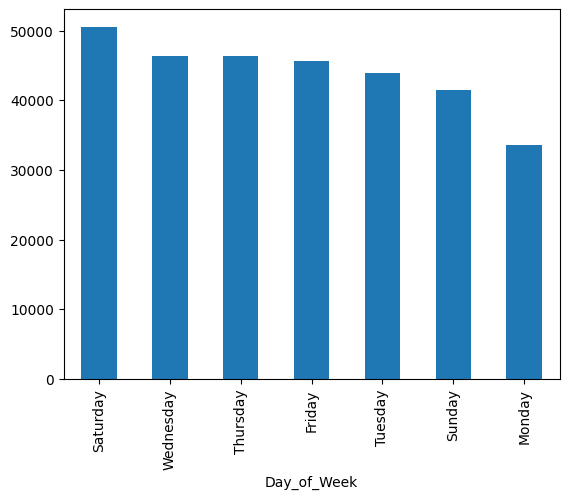

In [ ]:
df['Day_of_Week'].value_counts().plot(kind="bar")

In [ ]:
df['Day_Type'] = df['Accident Date'].dt.dayofweek.apply(
    lambda x: 'Weekend' if x >= 5 else 'Weekday')

In [ ]:

df['Day_Type'].value_counts()

,count
Day_Type,
Weekday,215862
Weekend,92093


<Axes: xlabel='Day_Type'>

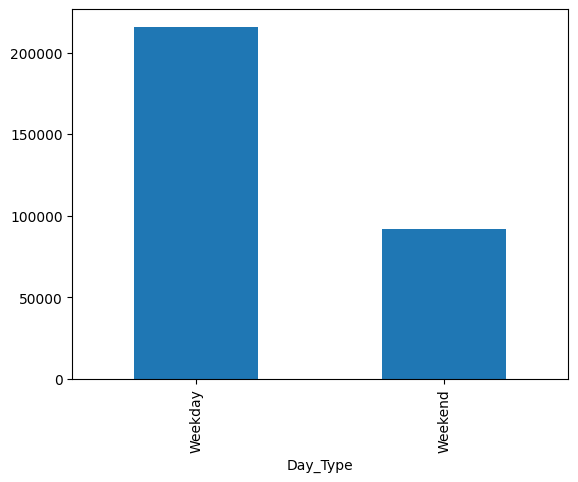

In [ ]:
df['Day_Type'].value_counts().plot(kind="bar")

- November had the most accidents (29,094), February the least (21,882) — no big seasonal swing.

- 2021 had more accidents (163,537) than 2022 (144,419) — a decent year-over-year drop.

- Saturday was the highest single day (50,529), Monday the lowest (33,543). Weekdays add up to more overall (215,863 vs 92,093), but that's just because there are more weekdays — Saturday alone still beats every individual weekday.

- Overall: accidents seem tied to when people drive more — weekends (especially Saturday) and slightly more toward year-end.

In [ ]:
df.shape

(307955, 24)

In [ ]:
df['Junction_Control'].value_counts()

,count
Junction_Control,
Give way or uncontrolled,150039
Data missing or out of range,98047
Auto traffic signal,32254
Not at junction or within 20 metres,25378
Stop sign,1684
Authorised person,460
Auto traffic sigl,93


<Axes: xlabel='Junction_Control'>

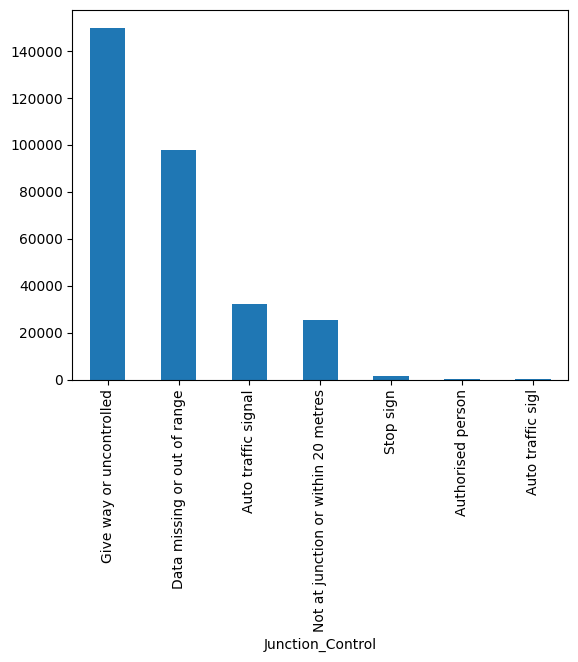

In [ ]:
df['Junction_Control'].value_counts().plot(kind="bar")

In [ ]:
#Accident_Severity
df["Accident_Severity"] = df["Accident_Severity"].replace(
    "Fetal", "Fatal"
)

In [ ]:

df["Accident_Severity"].unique()

array(['Serious', 'Slight', 'Fatal'], dtype=object)

In [ ]:
df["Accident_Severity"].value_counts()

,count
Accident_Severity,
Slight,263264
Serious,40738
Fatal,3953


<Axes: ylabel='count'>

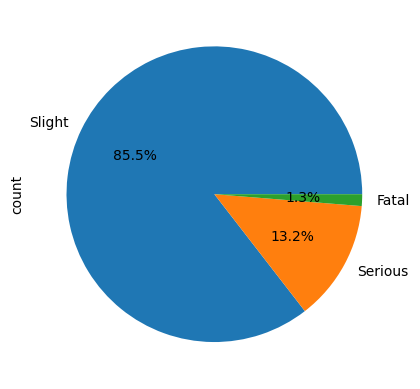

In [ ]:
df["Accident_Severity"].value_counts().plot(kind="pie",autopct="%1.1f%%")

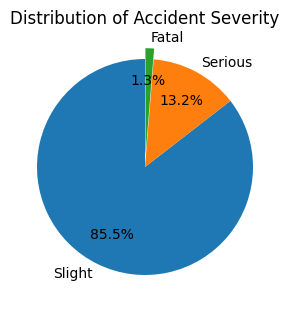

In [ ]:
ax = df['Accident_Severity'].value_counts().plot(
    kind="pie", autopct="%1.1f%%", startangle=90, pctdistance=0.7,
    labeldistance=1.1, figsize=(3,4), explode=[0, 0, 0.1])
ax.set_ylabel("")
plt.title("Distribution of Accident Severity")
plt.tight_layout()
plt.show()

- Slight accidents were by far the most common, with 263,265 cases, meaning most accidents in the dataset resulted in lower severity.
- Serious accidents (40,738) were much less common, while Fatal accidents (3,953) were rare compared to the other two categories.
- The large difference between the three categories shows that the dataset is strongly imbalanced, with the Slight category dominating the data.

In [ ]:
df["Latitude"].describe()

,Latitude
count,307955.000000
mean,52.486754
std,1.338631
min,49.914488
25%,51.485231
50%,52.225806
75%,53.415416
max,60.598055


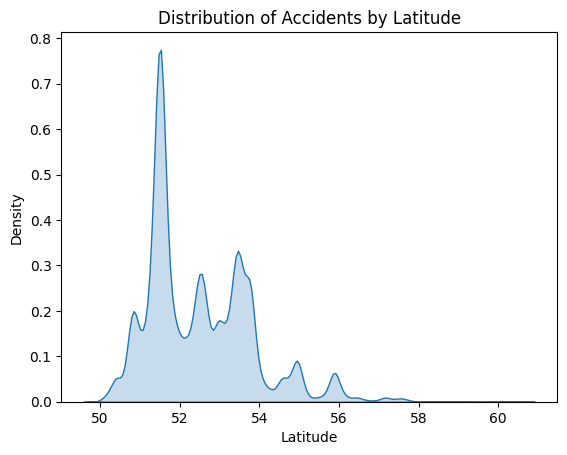

In [ ]:


sns.kdeplot(df['Latitude'], fill=True)
plt.title('Distribution of Accidents by Latitude')
plt.xlabel('Latitude')
plt.ylabel('Density')
plt.show()

In [ ]:
df['Latitude'].skew()

np.float64(0.9986939517716483)

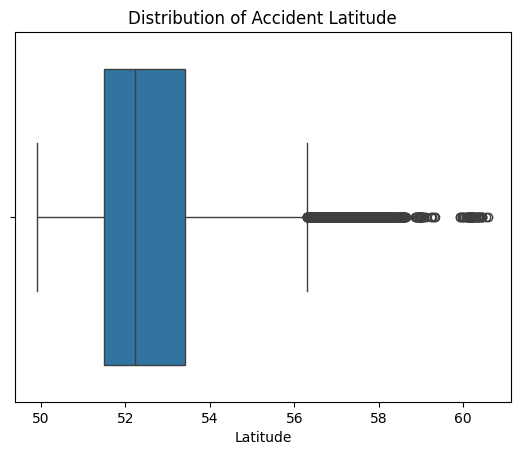

In [ ]:
sns.boxplot(x=df['Latitude'])
plt.title('Distribution of Accident Latitude')
plt.xlabel('Latitude')
plt.show()

In [ ]:
df['Latitude_Range'] = pd.cut(
    df['Latitude'],
    bins=[49.9, 51, 52, 53, 54, 60.6],
    labels=['49.9–51', '51–52', '52–53', '53–54', '54–60.6']
)

df['Latitude_Range'].value_counts().sort_index()

,count
Latitude_Range,
49.9–51,26710
51–52,117336
52–53,60335
53–54,72803
54–60.6,30771


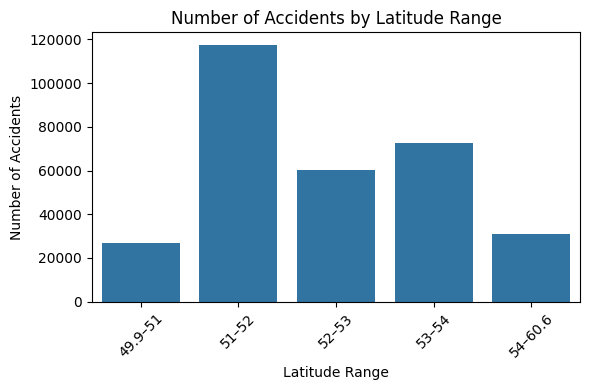

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x='Latitude_Range',
    order=df['Latitude_Range'].cat.categories
)

plt.title('Number of Accidents by Latitude Range')
plt.xlabel('Latitude Range')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

- The accident locations are not evenly distributed across all latitude values; they are concentrated within certain latitude ranges.
- The 51–52 latitude range recorded the highest number of accidents (117,336), showing a major concentration of accident records in this geographical range.
- This suggests that location plays an important role in accident distribution, although latitude alone cannot explain why accidents occur more frequently in a particular area.

In [ ]:

df['Light_Conditions'].value_counts()

,count
Light_Conditions,
Daylight,227274
Darkness - lights lit,60090
Darkness - no lighting,16525
Darkness - lighting unknown,2924
Darkness - lights unlit,1142


In [ ]:


df['Light_Conditions'].value_counts(normalize=True) * 100

,proportion
Light_Conditions,
Daylight,73.801042
Darkness - lights lit,19.512591
Darkness - no lighting,5.366044
Darkness - lighting unknown,0.949489
Darkness - lights unlit,0.370833


<Axes: xlabel='Light_Conditions'>

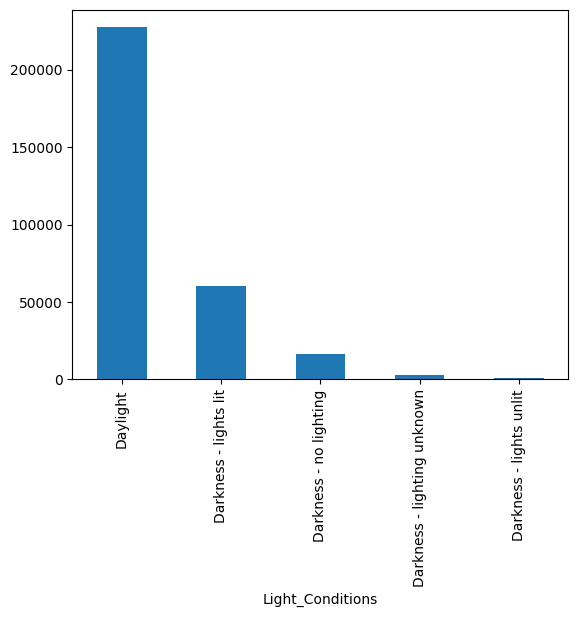

In [ ]:



df['Light_Conditions'].value_counts().plot(kind="bar")

- Most accidents occurred during Daylight (227,275 cases), followed by Darkness with lights lit.
- This shows that a large number of accidents occur even in good visibility conditions.
- However, this does not mean daylight is more dangerous, as more vehicles and traffic are likely present during daytime.

In [ ]:
df['Local_Authority_(District)'].value_counts()

,count
Local_Authority_(District),
Birmingham,6165
Leeds,4140
Manchester,3132
Bradford,3006
Westminster,2811
...,...
Clackmannanshire,25
Alnwick,20
South Shropshire,18


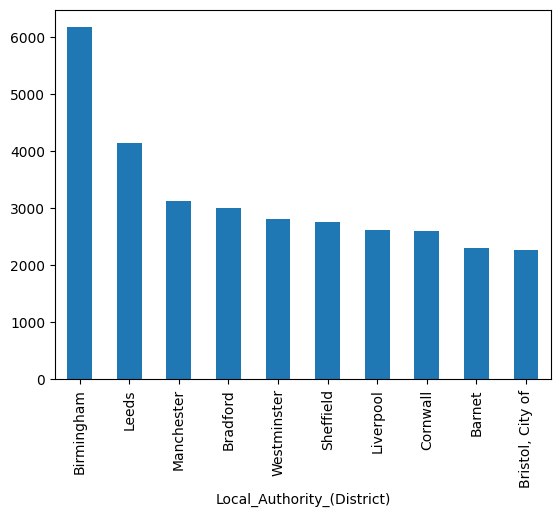

In [ ]:
top_authorities = df['Local_Authority_(District)'].value_counts().head(10).plot(kind="bar")


- Accident records are not evenly distributed across districts, with some districts recording significantly more accidents than others.
- Birmingham recorded the highest number of accidents, followed by districts such as Leeds and Manchester.
- This suggests that location and district-level factors may influence accident occurrence.

In [ ]:
df["Carriageway_Hazards"].value_counts()

,count
Carriageway_Hazards,
Unknown,302531
Other object on road,2243
Any animal in carriageway (except ridden horse),1620
Pedestrian in carriageway - not injured,715
Previous accident,511
Vehicle load on road,335


- The Carriageway Hazards variable contains a very high proportion of unknown values (approximately 98.2%), which resulted from missing values being replaced with the category ‘Unknown’ during preprocessing. The known hazard categories account for only a small proportion of the records.

In [ ]:
df["Longitude"].describe()

,Longitude
count,307955.000000
mean,-1.368809
std,1.356084
min,-7.516225
25%,-2.247853
50%,-1.349137
75%,-0.206801
max,1.759398


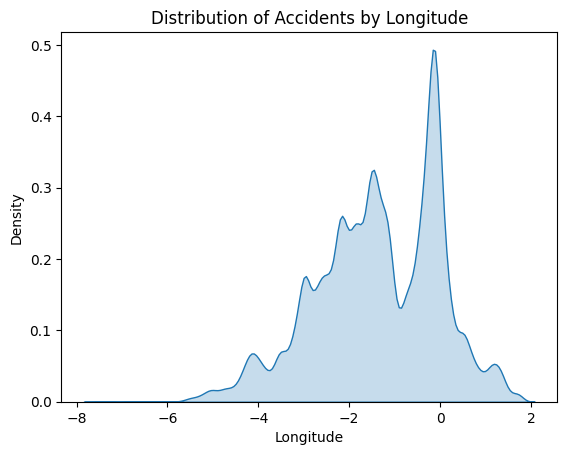

In [ ]:
sns.kdeplot(df['Longitude'], fill=True)
plt.title('Distribution of Accidents by Longitude')
plt.xlabel('Longitude')
plt.ylabel('Density')
plt.show()

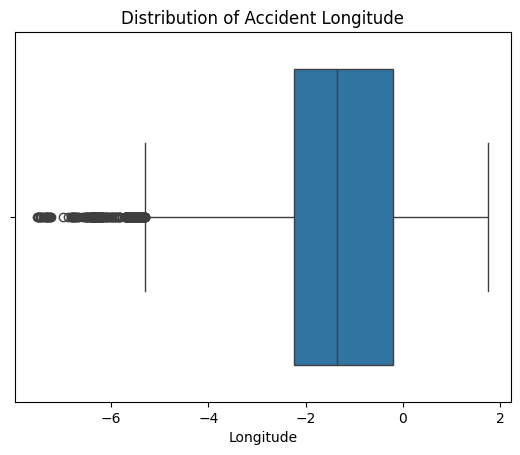

In [ ]:

sns.boxplot(x=df['Longitude'])
plt.title('Distribution of Accident Longitude')
plt.xlabel('Longitude')
plt.show()

In [ ]:
df['Longitude_Range'] = pd.cut(
    df['Longitude'],
    bins=[-7.6, -6, -4, -2, 0, 2],
    labels=['-7.6 to -6', '-6 to -4', '-4 to -2', '-2 to 0', '0 to 2']
)

df['Longitude_Range'].value_counts().sort_index()

,count
Longitude_Range,
-7.6 to -6,128
-6 to -4,12922
-4 to -2,84752
-2 to 0,169459
0 to 2,40694


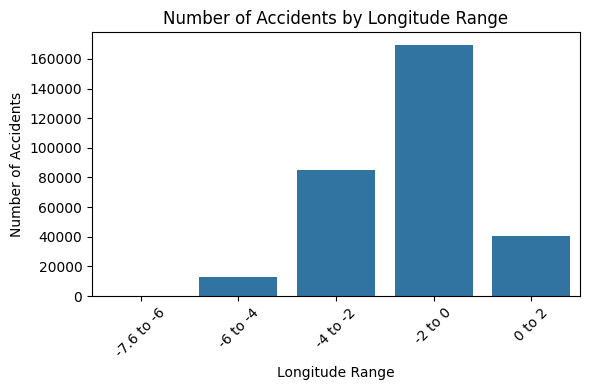

In [ ]:

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x='Longitude_Range',
    order=df['Longitude_Range'].cat.categories
)

plt.title('Number of Accidents by Longitude Range')
plt.xlabel('Longitude Range')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


- Accident records are concentrated within certain longitude ranges, showing that accidents are not evenly distributed geographically.
- Similar to latitude, longitude helps identify the geographical concentration of accident locations.
- However, longitude alone does not explain why accidents are more common in a particular locatio

In [ ]:
df["Number_of_Casualties"].describe()

,Number_of_Casualties
count,307955.00000
mean,1.35689
std,0.81587
min,1.00000
25%,1.00000
50%,1.00000
75%,1.00000
max,48.00000


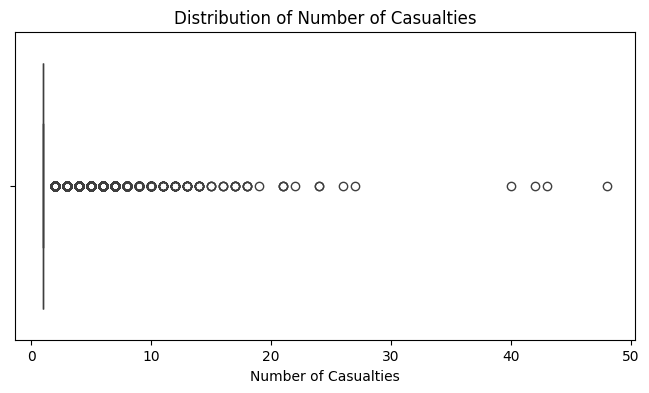

In [ ]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df['Number_of_Casualties'])

plt.xlabel('Number of Casualties')
plt.title('Distribution of Number of Casualties')
plt.show()

In [ ]:



df['Casualty_Range'] = pd.cut(
    df['Number_of_Casualties'],
    bins=[0, 1, 2, 3, 4, 5, 10, 20, 50],
    labels=[
        '1',
        '2',
        '3',
        '4',
        '5',
        '6–10',
        '11–20',
        '21–50'
    ]
)
df['Casualty_Range'].value_counts().sort_index()


,count
Casualty_Range,
1,235078
2,50086
3,14337
4,5348
5,1896
6–10,1135
11–20,63
21–50,12


<Axes: xlabel='Casualty_Range'>

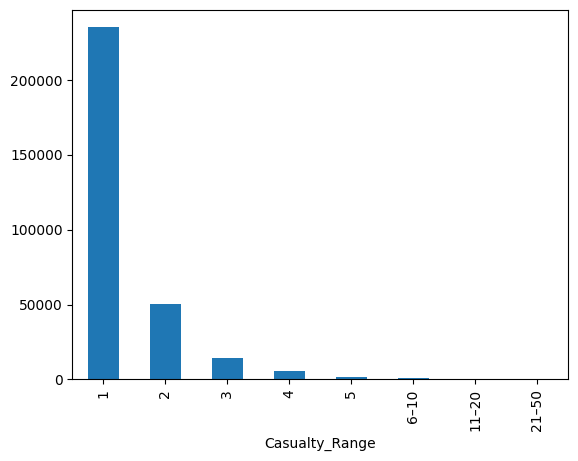

In [ ]:

df['Casualty_Range'].value_counts().sort_index().plot(kind="bar")

- Most accidents involved only one casualty (235,079 cases).
- The number of accidents decreases as the number of casualties increases, meaning accidents involving many casualties are reltively uncommon.
- This shows a right-skewed distribution, with most cases concentrated at lower casualty counts

In [ ]:




df["Number_of_Vehicles"].describe()

,Number_of_Vehicles
count,307955.000000
mean,1.829069
std,0.710466
min,1.000000
25%,1.000000
50%,2.000000
75%,2.000000
max,32.000000


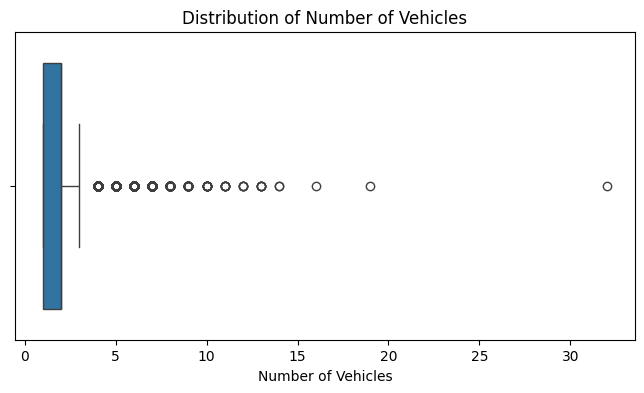

In [ ]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df['Number_of_Vehicles'])

plt.xlabel('Number of Vehicles')
plt.title('Distribution of Number of Vehicles')
plt.show()

In [ ]:

df['Number_of_Vehicles'].value_counts().sort_index()

,count
Number_of_Vehicles,
1,93340
2,183589
3,24224
4,5076
5,1127
6,346
7,127
8,63
9,31


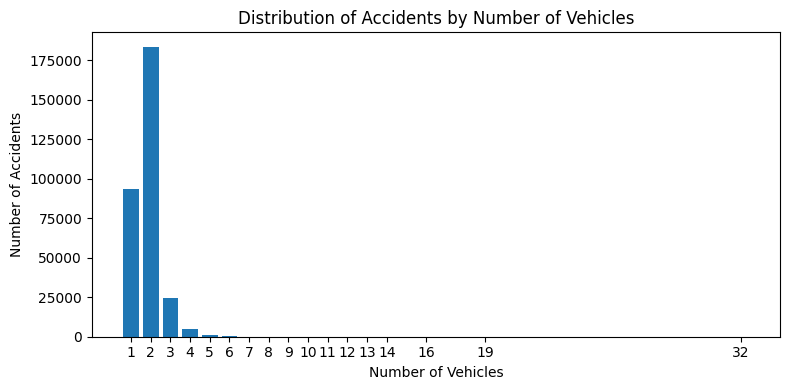

In [ ]:






vehicle_counts = df['Number_of_Vehicles'].value_counts().sort_index()

plt.figure(figsize=(8, 4))
plt.bar(vehicle_counts.index, vehicle_counts.values)

plt.xlabel('Number of Vehicles')
plt.ylabel('Number of Accidents')
plt.title('Distribution of Accidents by Number of Vehicles')

plt.xticks(vehicle_counts.index)
plt.tight_layout()
plt.show()

In [ ]:

df["Police_Force"].value_counts()

,count
Police_Force,
Metropolitan Police,46789
West Midlands,13509
West Yorkshire,12015
Greater Manchester,11954
Thames Valley,11483
Kent,9995
Hampshire,9492
Lancashire,9143
Devon and Cornwall,8804


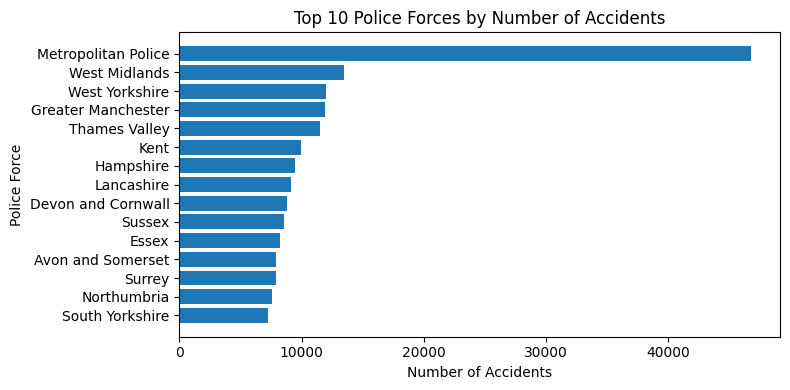

In [ ]:
top_police = df['Police_Force'].value_counts().head(15)
plt.figure(figsize=(8, 4))
plt.barh(top_police.index[::-1], top_police.values[::-1])
plt.xlabel('Number of Accidents')
plt.ylabel('Police Force')
plt.title('Top 10 Police Forces by Number of Accidents')
plt.tight_layout()
plt.show()

- Police Force: The Police Force variable contains 51 categories with varying numbers of accident records. The Metropolitan Police has the highest number of recorded accidents, with 46,789 cases, followed by West Midlands with 13,509 cases and West Yorkshire with 12,016 cases. In contrast, Dumfries and Galloway has the lowest number of records with 388 cases. This indicates substantial variation in the number of recorded accidents across different police-force areas

In [ ]:
df["Road_Surface_Conditions"].value_counts()

,count
Road_Surface_Conditions,
Dry,208961
Wet or damp,81468
Frost or ice,12077
Snow,4758
Flood over 3cm. deep,374
Unknown,317


<Axes: xlabel='Road_Surface_Conditions'>

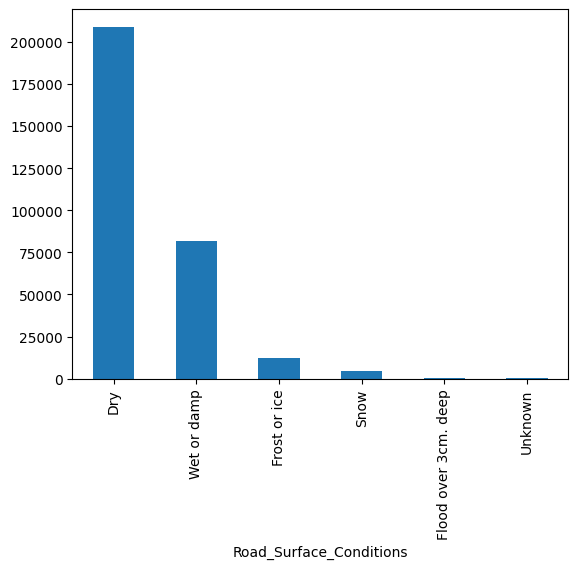

In [ ]:
df["Road_Surface_Conditions"].value_counts().plot(kind="bar")

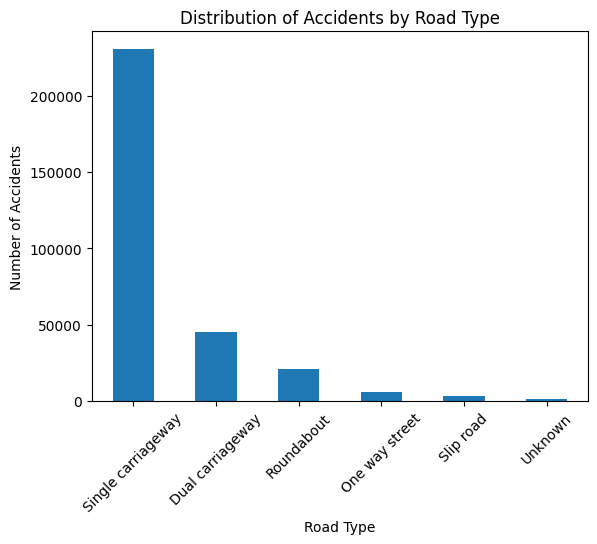

In [ ]:



df['Road_Type'].value_counts().plot(kind='bar')
plt.xlabel('Road Type')
plt.ylabel('Number of Accidents')
plt.title('Distribution of Accidents by Road Type')
plt.xticks(rotation=45)
plt.show()



- Most accidents occurred on Dry road surfaces (208,961 cases), followed by Wet or damp surfaces (81,468 cases).
- Accidents under snowy, icy, or flooded road conditions were comparatively rare.
- The higher number of accidents on dry roads does not necessarily mean dry roads are more dangerous, as dry conditions may simply have more traffic and road usage

In [ ]:
df["Speed_limit"].describe()

,Speed_limit
count,307955.000000
mean,38.865678
std,14.032773
min,10.000000
25%,30.000000
50%,30.000000
75%,50.000000
max,70.000000


<Axes: >

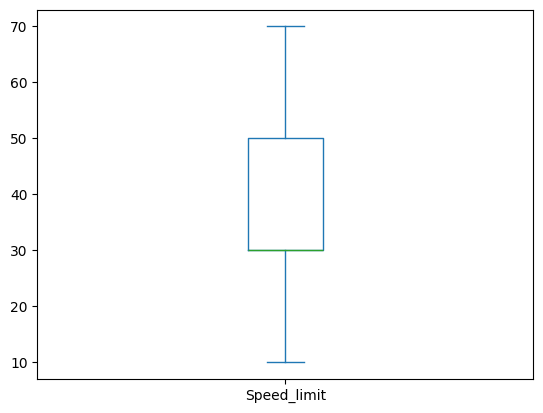

In [ ]:
df["Speed_limit"].plot(kind="box")

<Axes: ylabel='Density'>

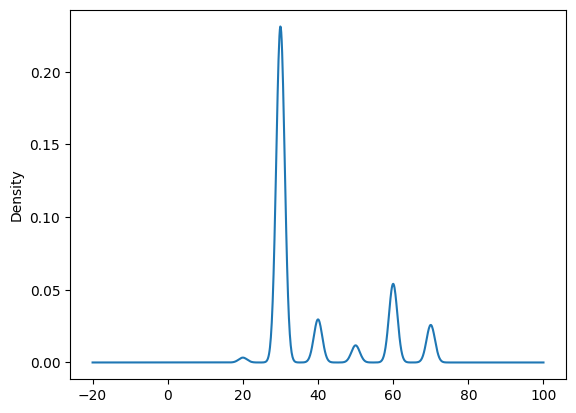

In [ ]:


df["Speed_limit"].plot(kind="kde")

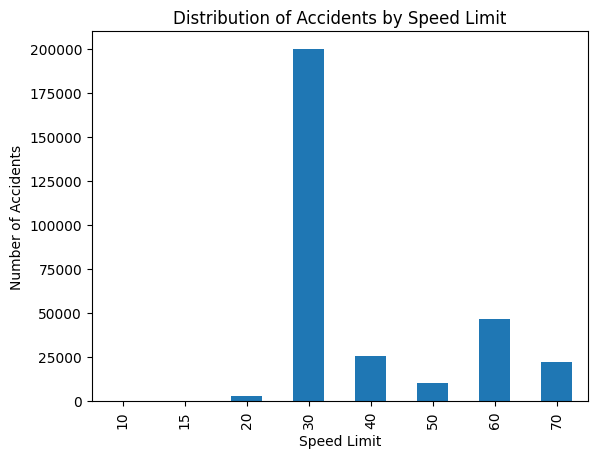

In [ ]:
df['Speed_limit'].value_counts().sort_index().plot(kind='bar')

plt.xlabel('Speed Limit')
plt.ylabel('Number of Accidents')
plt.title('Distribution of Accidents by Speed Limit')
plt.show()

- Speed limits in the dataset range from 10 to 70 mph, showing that accidents occurred across different speed-limit zones.
- The average speed limit is around 39 mph, while the median is 30 mph, suggesting that many accidents occurred on roads with lower speed limits.
- The data is spread across common speed-limit values rather than being concentrated at only one value

In [ ]:
df['Time'].dtype

dtype('O')

In [ ]:
df['Time'] = pd.to_datetime(df['Time'], format='%H:%M:%S')
df['Hour'] = df['Time'].dt.hour

In [ ]:

df['Hour'].value_counts()

,count
Hour,
17,26964
16,24902
15,24151
8,22552
18,21063
14,19067
13,18971
12,18342
11,16141


<Axes: xlabel='Hour'>

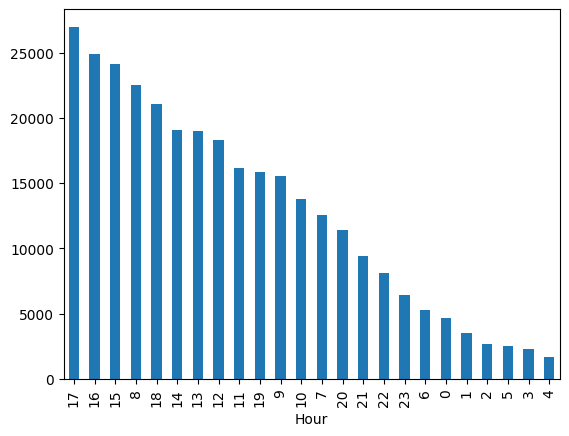

In [ ]:
df['Hour'].value_counts().plot(kind="bar")

In [ ]:
df["Urban_or_Rural_Area"].value_counts()

,count
Urban_or_Rural_Area,
Urban,198526
Rural,109429


- Accident occurrence varies clearly throughout the day, with the highest number of accidents at 17:00 (5 PM), with 26,964 cases.
- Accident counts are also relatively high during the afternoon (around 3–6 PM) and show another noticeable peak around 8 AM, which may correspond to periods of higher travel activity.
- Accident counts are lowest during the early morning hours, especially around 4 AM (1,721 cases).

<Axes: xlabel='Urban_or_Rural_Area'>

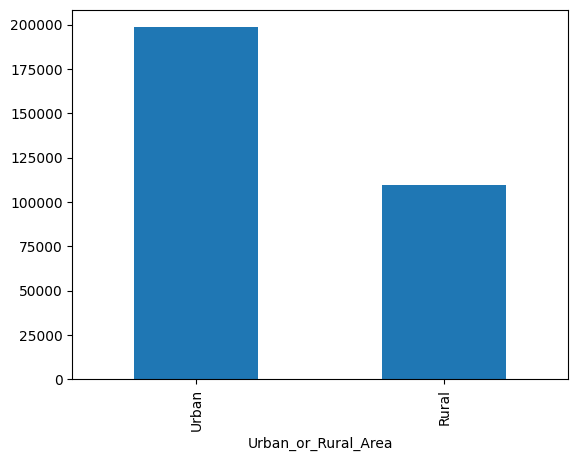

In [ ]:
df["Urban_or_Rural_Area"].value_counts().plot(kind="bar")

- A larger number of accidents occurred in Urban areas (198,526 cases) compared to Rural areas (109,430 cases).
This may be linked to higher traffic density and more frequent road usage in urban areas.
- However, the higher number of accidents in urban areas does not necessarily mean urban roads are more dangerous, as exposure to traffic may be much greater.

In [ ]:
df["Weather_Conditions"].value_counts()

,count
Weather_Conditions,
Fine no high winds,244483
Raining no high winds,34874
Other,8802
Unknown,6057
Snowing no high winds,4839
Raining + high winds,3524
Fine + high winds,3148
Fog or mist,1690
Snowing + high winds,538


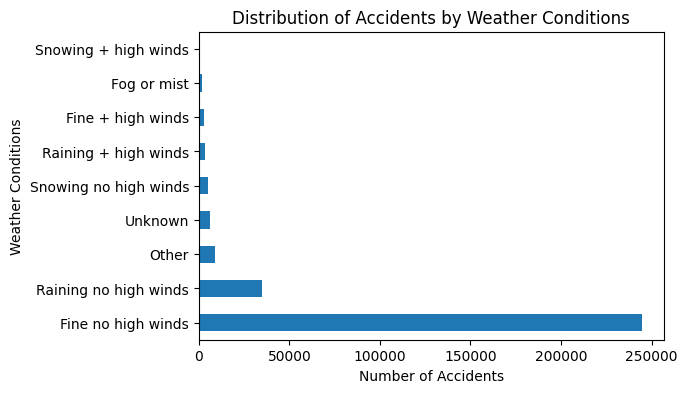

In [ ]:

df['Weather_Conditions'].value_counts().plot(
    kind='barh',
    figsize=(6, 4))
plt.xlabel('Number of Accidents')
plt.ylabel('Weather Conditions')
plt.title('Distribution of Accidents by Weather Conditions')
plt.show()

- Most accidents occurred during Fine weather with no high winds (244,484 cases), followed by Raining with no high winds (34,874 cases).
- Accidents were much less common during fog, snow, and high-wind conditions.
- The high number of accidents in fine weather shows that accidents are not limited to poor weather conditions.
However, this does not mean fine weather is more dangerous, as more people may travel and traffic volume may be higher during normal weather conditions.

In [ ]:
df['Vehicle_Type'].value_counts()

,count
Vehicle_Type,
Car,239780
Van / Goods 3.5 tonnes mgw or under,15692
Motorcycle over 500cc,11226
Bus or coach (17 or more pass seats),8686
Motorcycle 125cc and under,6852
Goods 7.5 tonnes mgw and over,6532
Taxi/Private hire car,5542
Motorcycle 50cc and under,3703
Motorcycle over 125cc and up to 500cc,3285


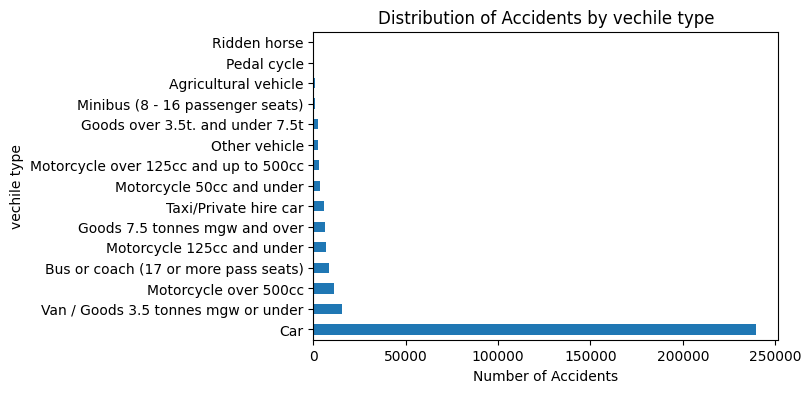

In [ ]:
df['Vehicle_Type'].value_counts().plot(
    kind='barh',
    figsize=(6, 4)
)
plt.xlabel('Number of Accidents')
plt.ylabel('vechile type')
plt.title('Distribution of Accidents by vechile type')
plt.show()

- Cars were involved in by far the highest number of accidents (239,781 cases), making them the dominant vehicle type in the dataset.
- Other vehicle types, such as vans, motorcycles, buses, and goods vehicles, had substantially fewer recorded accidents.
- This pattern may mainly reflect the higher number and usage of cars on the road, rather than proving that cars are inherently more accident-prone.

## Overall Insights from Univariate Analysis
- Accident occurrence varied across time, date, location, and road conditions, showing that accidents are influenced by multiple factors.
- Most accidents were Slight in severity, while Serious and Fatal accidents were much less common.
- Accidents were more concentrated in certain locations, districts, and police force areas, rather than being evenly distributed geographically.
- Daylight, fine weather, dry roads, urban areas, and cars recorded the highest number of accidents; however, this may also reflect higher traffic and road usage in these conditions.
- Accident occurrence was higher during certain hours of the day, particularly around peak travel periods.
- Most accidents involved one casualty and a small number of vehicles.
- These findings provide an overall understanding of accident patterns and help identify important variables for further bivariate analysis and accident severity prediction.

##  Bivariate Analysis


In [ ]:
df.groupby(["Month","Accident_Severity"])["Accident_Severity"].count()


Month      Accident_Severity
April      Fatal                  312
           Serious               3451
           Slight               20461
August     Fatal                  359
           Serious               3497
           Slight               21645
December   Fatal                  255
           Serious               2667
           Slight               20411
February   Fatal                  378
           Serious               2681
           Slight               18823
January    Fatal                  305
           Serious               2875
           Slight               20199
July       Fatal                  313
           Serious               3665
           Slight               22974
June       Fatal                  309
           Serious               3754
           Slight               22684
March      Fatal                  370
           Serious               3339
           Slight               21833
May        Fatal                  403
           Serious               3716
           Slight               22063
November   Fatal                  299
           Serious               3522
           Slight               25273
October    Fatal                  325
           Serious               3754
           Slight               24289
September  Fatal                  325
           Serious               3817
           Slight               22609
Name: Accident_Severity, dtype: int64

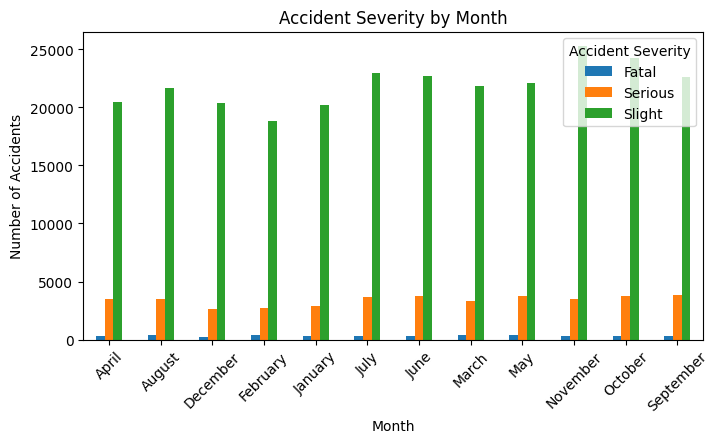

In [ ]:

df.groupby(["Month", "Accident_Severity"]).size().unstack().plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Accident Severity by Month")
plt.xlabel("Month")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=45)
plt.legend(title="Accident Severity")
plt.show()

- Slight accidents are the highest in every month by a very large margin.
- Serious accidents are much lower than slight accidents.
- Fatal accidents are the lowest and remain relatively small across all months.
- Although the total number of accidents changes somewhat from month to month, the overall pattern of severity remains similar

In [ ]:
df.groupby(["Year","Accident_Severity"])["Accident_Severity"].count()

Year  Accident_Severity
2021  Fatal                  2404
      Serious               21961
      Slight               139171
2022  Fatal                  1549
      Serious               18777
      Slight               124093
Name: Accident_Severity, dtype: int64

<Axes: xlabel='Year,Accident_Severity'>

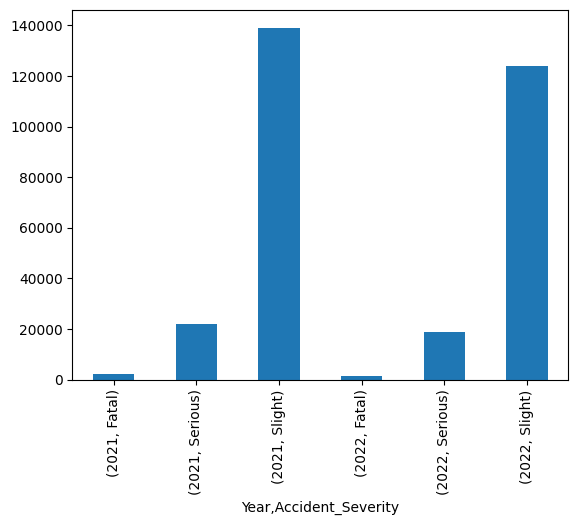

In [ ]:

df.groupby(["Year","Accident_Severity"])["Accident_Severity"].count().plot(kind="bar")

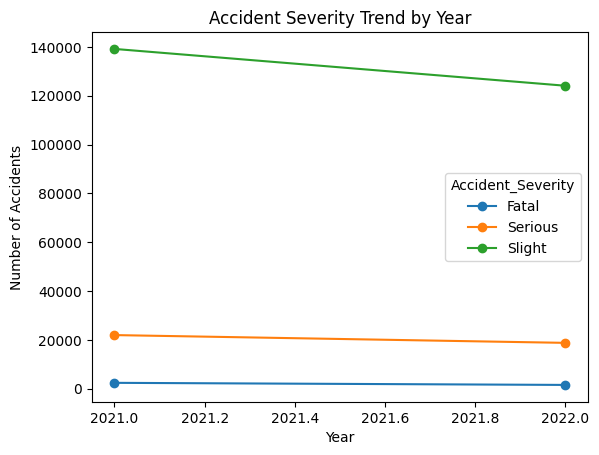

In [ ]:
year_severity = pd.crosstab(df["Year"], df["Accident_Severity"])

year_severity.plot(kind="line", marker="o")

plt.title("Accident Severity Trend by Year")
plt.xlabel("Year")
plt.ylabel("Number of Accidents")
plt.show()

- Slight accidents decreased from about 139,000 in 2021 to 124,000 in 2022.
Serious accidents also decreased from approximately 22,000 to 18,500.
- Fatal accidents decreased slightly as well.
- Overall, all three severity categories show a decrease in 2022 compared to 2021.
- Slight accidents remain by far the most common severity level in both years.

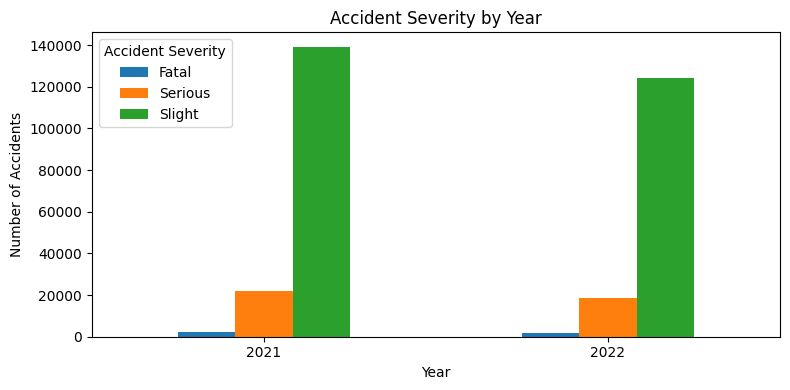

In [ ]:
year_severity = df.groupby(
    ["Year", "Accident_Severity"]
).size().unstack()
year_severity.plot(
    kind="bar",
    figsize=(8, 4)
)
plt.title("Accident Severity by Year")
plt.xlabel("Year")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=0)
plt.legend(title="Accident Severity")
plt.tight_layout()
plt.show()

- 2021 has more Slight accidents than 2022.
- 2021 also has more Serious accidents than 2022.
- Fatal accidents appear relatively similar in both years.
- Slight accidents are the most common severity category in both years, followed by Serious and Fatal accidents.

In [ ]:
df.groupby(["Day_Type","Accident_Severity"])["Accident_Severity"].count()

Day_Type  Accident_Severity
Weekday   Fatal                  2626
          Serious               28229
          Slight               185007
Weekend   Fatal                  1327
          Serious               12509
          Slight                78257
Name: Accident_Severity, dtype: int64

<Axes: xlabel='Day_Type'>

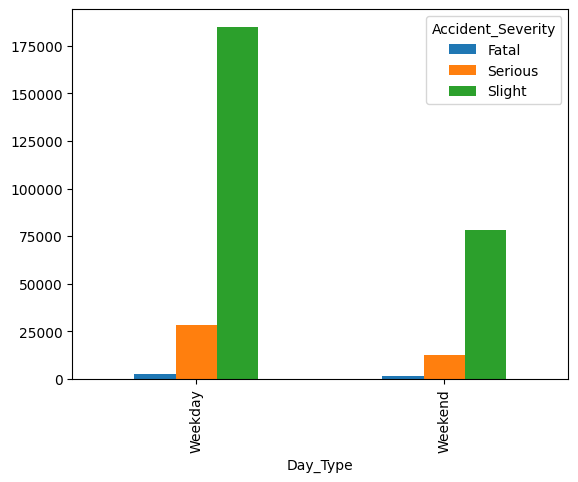

In [ ]:
df.groupby(["Day_Type","Accident_Severity"])["Accident_Severity"].size().unstack().plot(kind="bar")

- The analysis shows that accidents of all severity levels occur more frequently on weekdays than on weekends. Slight accidents constitute the majority of accidents in both categories, followed by serious accidents, while fatal accidents are the least frequent. The higher number of accidents on weekdays may be associated with increased traffic volume due to work, school, and other daily activities.

In [ ]:
df.groupby(["Accident_Severity","Junction_Control"])["Junction_Control"].count()

Accident_Severity  Junction_Control                   
Fatal              Authorised person                           2
                   Auto traffic signal                       302
                   Data missing or out of range             1916
                   Give way or uncontrolled                 1223
                   Not at junction or within 20 metres       499
                   Stop sign                                  11
Serious            Authorised person                          42
                   Auto traffic sigl                          10
                   Auto traffic signal                      3274
                   Data missing or out of range            15012
                   Give way or uncontrolled                18236
                   Not at junction or within 20 metres      3990
                   Stop sign                                 174
Slight             Authorised person                         416
                   Auto traffic sigl                          83
                   Auto traffic signal                     28678
                   Data missing or out of range            81119
                   Give way or uncontrolled               130580
                   Not at junction or within 20 metres     20889
                   Stop sign                                1499
Name: Junction_Control, dtype: int64

In [ ]:
df

,Accident_Index,Accident Date,Day_of_Week,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,Local_Authority_(District),Carriageway_Hazards,...,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type,Month,Year,Day_Type,Latitude_Range,Longitude_Range,Casualty_Range,Hour
0,200901BS70001,2021-01-01,Friday,Give way or uncontrolled,T or staggered junction,Serious,51.512273,Daylight,Kensington and Chelsea,Unknown,...,Urban,Fine no high winds,Car,January,2021,Weekday,51–52,-2 to 0,1,15
1,200901BS70002,2021-01-05,Tuesday,Give way or uncontrolled,Crossroads,Serious,51.514399,Daylight,Kensington and Chelsea,Unknown,...,Urban,Fine no high winds,Taxi/Private hire car,January,2021,Weekday,51–52,-2 to 0,11–20,10
2,200901BS70003,2021-01-04,Monday,Give way or uncontrolled,T or staggered junction,Slight,51.486668,Daylight,Kensington and Chelsea,Unknown,...,Urban,Fine no high winds,Taxi/Private hire car,January,2021,Weekday,51–52,-2 to 0,1,14
3,200901BS70004,2021-01-05,Tuesday,Auto traffic signal,T or staggered junction,Serious,51.507804,Daylight,Kensington and Chelsea,Unknown,...,Urban,Other,Motorcycle over 500cc,January,2021,Weekday,51–52,-2 to 0,1,8
4,200901BS70005,2021-01-06,Wednesday,Auto traffic signal,Crossroads,Serious,51.482076,Darkness - lights lit,Kensington and Chelsea,Unknown,...,Urban,Fine no high winds,Car,January,2021,Weekday,51–52,-2 to 0,1,17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307968,201091NM01760,2022-02-18,Friday,Data missing or out of range,Not at junction or within 20 metres,Slight,57.374005,Daylight,Highland,Unknown,...,Rural,Fine no high winds,Car,February,2022,Weekday,54–60.6,-4 to -2,2,7
307969,201091NM01881,2022-02-21,Monday,Data missing or out of range,Not at junction or within 20 metres,Slight,57.232273,Darkness - no lighting,Highland,Unknown,...,Rural,Fine no high winds,Car,February,2022,Weekday,54–60.6,-4 to -2,1,3
307970,201091NM01935,2022-02-23,Wednesday,Give way or uncontrolled,T or staggered junction,Slight,57.585044,Daylight,Highland,Unknown,...,Rural,Fine no high winds,Car,February,2022,Weekday,54–60.6,-4 to -2,1,9
307971,201091NM01964,2022-02-23,Wednesday,Give way or uncontrolled,T or staggered junction,Serious,57.214898,Darkness - no lighting,Highland,Unknown,...,Rural,Fine no high winds,Motorcycle over 500cc,February,2022,Weekday,54–60.6,-4 to -2,1,18


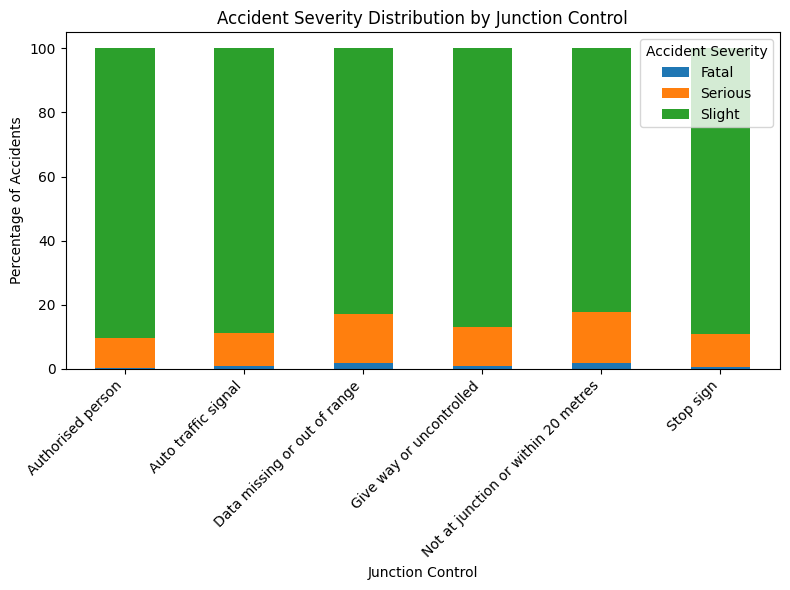

In [ ]:
# Fix inconsistent category name
df['Junction_Control'] = df['Junction_Control'].replace(
    'Auto traffic sigl',
    'Auto traffic signal'
)

# Create cross-tabulation
junction_severity = pd.crosstab(
    df['Junction_Control'],
    df['Accident_Severity']
)

# Convert counts into percentages
junction_percentage = junction_severity.div(
    junction_severity.sum(axis=1),
    axis=0
) * 100

# Plot
junction_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 6)
)

plt.title('Accident Severity Distribution by Junction Control')
plt.xlabel('Junction Control')
plt.ylabel('Percentage of Accidents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Accident Severity')
plt.tight_layout()

plt.show()

- Slight accidents form the largest proportion across most Junction Control categories.
- Auto traffic signals and stop signs have a particularly high proportion of Slight accidents, compared with Serious and Fatal accidents.
- The categories Data missing or out of range and Not at junction or within 20 metres show a relatively higher proportion of Serious accidents compared with some other categories.
- Fatal accidents represent the smallest proportion for almost all Junction Control categories.
- Give way or uncontrolled junctions have a large number of accidents in the original count data, but total accident counts alone should not be interpreted as indicating greater danger because traffic volume and exposure are not considered

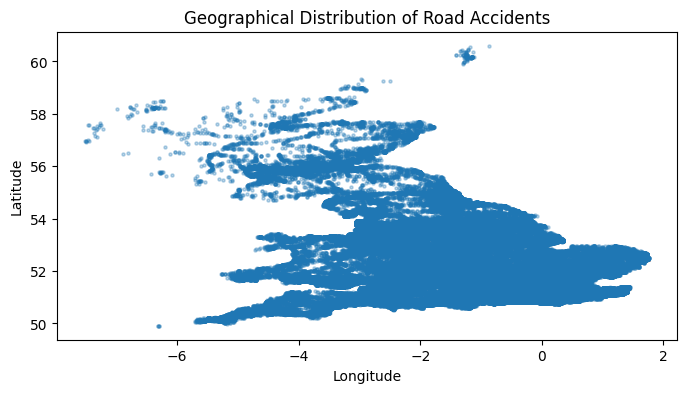

In [ ]:

#Longitude and Latitude or Geographical distribution of the road accidents
plt.figure(figsize=(8, 4))
plt.scatter(
    df['Longitude'],
    df['Latitude'],
    alpha=0.3,
    s=5
)
plt.title('Geographical Distribution of Road Accidents')
plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.show()

- The accident locations form a shape corresponding to the geographical area covered by your dataset.
- There are dense clusters of points, indicating locations where many accidents were recorded.
- Some areas have relatively fewer points, showing a lower concentration of recorded accidents.
- The dense overlap in the central and southern regions makes it difficult to distinguish individual accident locations because your dataset contains a very large number of records.

In [ ]:
pd.crosstab(df["Light_Conditions"],df["Accident_Severity"])

Accident_Severity,Fatal,Serious,Slight
Light_Conditions,,,
Darkness - lighting unknown,28,357,2539
Darkness - lights lit,862,8515,50713
Darkness - lights unlit,15,146,981
Darkness - no lighting,649,3078,12798
Daylight,2399,28642,196233


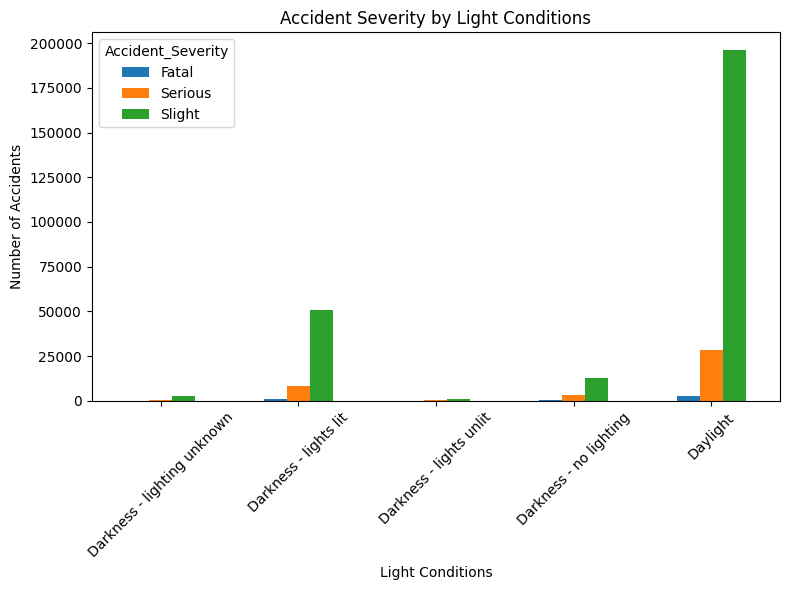

In [ ]:
pd.crosstab(df["Light_Conditions"],df["Accident_Severity"]).plot(kind="bar",figsize=(8,6))
plt.title("Accident Severity by Light Conditions")
plt.xlabel("Light Conditions")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=45)
plt.tight_layout()

- Daylight has the highest number of accidents, especially Slight accidents.
- Darkness with lights lit also has a considerable number of accidents.
- Other lighting conditions have comparatively fewer accidents.
In every light condition, Slight accidents are the most common.

In [ ]:
pd.crosstab(df["Local_Authority_(District)"],df["Accident_Severity"])

Accident_Severity,Fatal,Serious,Slight
Local_Authority_(District),,,
Aberdeen City,3,72,364
Aberdeenshire,21,182,478
Adur,7,48,229
Allerdale,9,64,451
Alnwick,2,1,17
...,...,...,...
Wychavon,13,78,515
Wycombe,7,92,679
Wyre,2,94,519


In [ ]:
=
district_accidents = pd.crosstab(
    df["Local_Authority_(District)"],
    df["Accident_Severity"]
)

district_accidents["Total"] = district_accidents.sum(axis=1)

top10 = district_accidents.sort_values("Total", ascending=False).head(10)

top10

Accident_Severity,Fatal,Serious,Slight,Total
Local_Authority_(District),,,,
Birmingham,57,706,5402,6165
Leeds,38,531,3571,4140
Manchester,24,313,2795,3132
Bradford,30,357,2619,3006
Westminster,189,387,2235,2811
Sheffield,16,325,2409,2750
Liverpool,22,373,2216,2611
Cornwall,43,255,2308,2606
Barnet,17,230,2055,2302


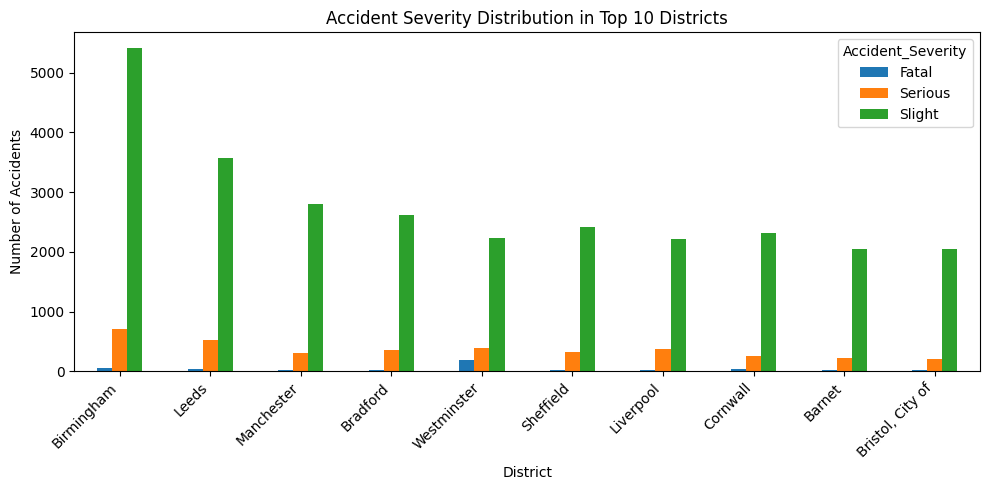

In [ ]:

top10[["Fatal", "Serious", "Slight"]].plot(
    kind="bar",
    figsize=(10, 5)
)
plt.title("Accident Severity Distribution in Top 10 Districts")
plt.xlabel("District")
plt.ylabel("Number of Accidents")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
district_accidents["Serious_Percentage"] = (
    district_accidents["Serious"] /
    district_accidents["Total"] * 100
)

district_accidents.sort_values(
    "Serious_Percentage", ascending=False
).head(10)

Accident_Severity,Fatal,Serious,Slight,Total,Serious_Percentage
Local_Authority_(District),,,,,
Ryedale,10,105,226,341,30.791789
Dumfries and Galloway,9,104,275,388,26.804124
Richmondshire,9,84,221,314,26.751592
Aberdeenshire,21,182,478,681,26.725404
Maldon,4,64,177,245,26.122449
South Northamptonshire,15,104,294,413,25.181598
Daventry,8,97,290,395,24.556962
Winchester,10,176,545,731,24.076607
Craven,14,87,268,369,23.577236


- Birmingham recorded the highest total number of accidents (6,165) among all districts, followed by Leeds (4,140) and Manchester (3,132).
- Slight accidents are the most common accident severity category in all of the top 10 districts, showing that most recorded accidents result in comparatively less severe outcomes.
- The number of total accidents alone does not indicate the severity of accidents. For example, Birmingham has the highest total number of accidents, but Westminster has a notably higher number of Fatal accidents despite having fewer total accidents.
- Ryedale has the highest Serious Accident Percentage (30.79%), meaning nearly 31 out of every 100 accidents recorded there were classified as Serious.
- Other districts, including Dumfries and Galloway, Richmondshire, and Aberdeenshire, also show a relatively high proportion of Serious accidents.

In [ ]:


pd.crosstab(df["Road_Surface_Conditions"],df["Accident_Severity"])

Accident_Severity,Fatal,Serious,Slight
Road_Surface_Conditions,,,
Dry,2693,28691,177577
Flood over 3cm. deep,13,53,308
Frost or ice,116,1259,10702
Snow,28,443,4287
Unknown,1,19,297
Wet or damp,1102,10273,70093


In [ ]:
road_surface_pct = pd.crosstab(
    df["Road_Surface_Conditions"],
    df["Accident_Severity"],
    normalize="index"
) * 100

road_surface_pct

Accident_Severity,Fatal,Serious,Slight
Road_Surface_Conditions,,,
Dry,1.288757,13.730313,84.980929
Flood over 3cm. deep,3.475936,14.171123,82.352941
Frost or ice,0.960503,10.424774,88.614722
Snow,0.588483,9.310635,90.100883
Unknown,0.315457,5.993691,93.690852
Wet or damp,1.352678,12.609859,86.037463


- Slight accidents are the most common for every road surface condition, ranging from approximately 82% to 94%.
- Flooded roads (over 3 cm deep) have the highest proportion of Fatal accidents (3.48%) among the listed conditions. However, be careful because this category has a very small number of observations, so the percentage may be less reliable.
- Wet or damp roads have a slightly higher Fatal accident percentage (1.35%) than dry roads (1.29%), while the proportion of Serious accidents is slightly lower.
- Dry roads have a relatively high Serious accident percentage (13.73%), although this does not mean dry roads cause more serious accidents—it only describes the distribution of severity among accidents recorded on dry roads.
Unknown has the highest Slight percentage (93.69%), but it also has very few observations, so avoid drawing strong conclusions from it.

In [ ]:
road_type_pct = pd.crosstab(
    df["Road_Type"],
    df["Accident_Severity"],
    normalize="index"
) * 100

road_type_pct

Accident_Severity,Fatal,Serious,Slight
Road_Type,,,
Dual carriageway,1.807944,11.723046,86.469010
One way street,0.822979,12.005809,87.171212
Roundabout,0.367911,8.514501,91.117588
Single carriageway,1.293176,14.069256,84.637568
Slip road,0.432900,8.503401,91.063698
Unknown,0.456323,10.691004,88.852673


In [ ]:
speed_limit_pct = pd.crosstab(
    df["Speed_limit"],
    df["Accident_Severity"],
    normalize="index"
) * 100

speed_limit_pct

Accident_Severity,Fatal,Serious,Slight
Speed_limit,,,
10,0.000000,0.000000,100.000000
15,0.000000,0.000000,100.000000
20,0.482925,13.004484,86.512591
30,0.768381,12.036134,87.195485
40,1.434698,12.846004,85.719298
50,2.158979,14.367026,83.473994
60,2.804417,18.829962,78.365621
70,2.240508,12.119315,85.640177


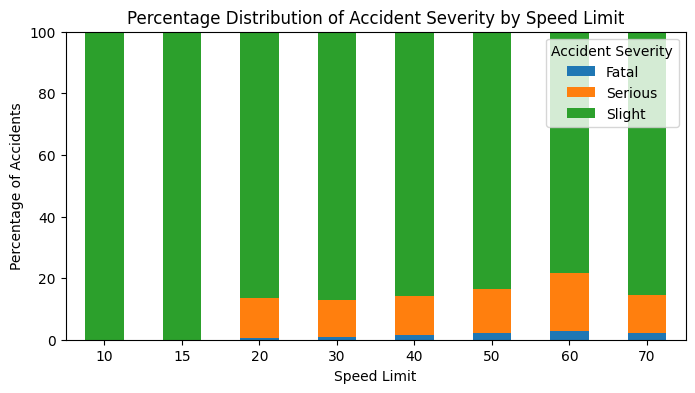

In [ ]:

speed_limit_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 4)
)

plt.title("Percentage Distribution of Accident Severity by Speed Limit")
plt.xlabel("Speed Limit")
plt.ylabel("Percentage of Accidents")
plt.legend(title="Accident Severity")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.show()

- At 10 and 15, almost 100% of accidents are Slight.
From 20 onwards, the proportion of Serious and Fatal accidents becomes more visible.
- The proportion of Serious accidents generally increases at higher speed limits, reaching a high level around 60.
- The Fatal accident proportion also appears higher at 50–70 compared with lower speed limits.
- Slight accidents still make up the largest percentage at every speed limit.

In [ ]:
time_pct = pd.crosstab(
    df["Hour"],
    df["Accident_Severity"],
    normalize="index"
) * 100

time_pct

Accident_Severity,Fatal,Serious,Slight
Hour,,,
0,3.149775,18.191558,78.658667
1,3.368242,18.143221,78.488537
2,3.808446,19.947210,76.244344
3,3.504976,19.558633,76.936391
4,3.660662,20.395119,75.944218
5,3.412284,17.021277,79.566439
6,2.180508,14.922260,82.897232
7,1.297771,12.898089,85.804140
8,0.718340,10.535651,88.746009


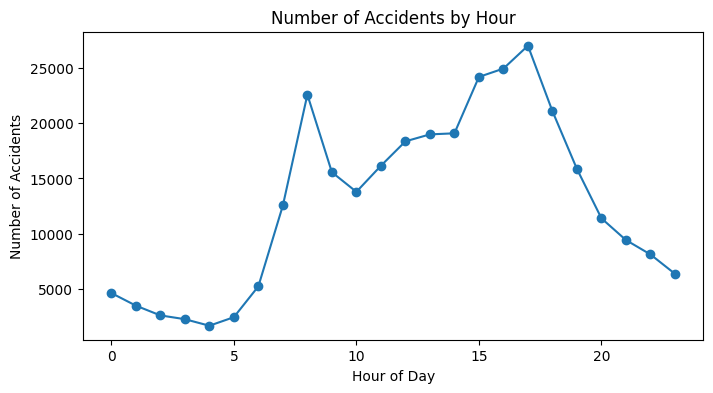

In [ ]:
df["Hour"].value_counts().sort_index().plot(
    kind="line",
    marker="o",
    figsize=(8, 4)
)

plt.title("Number of Accidents by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Accidents")
plt.show()

- Slight accidents are the most common at every hour, ranging from about 76% to 89%.
- The proportion of Fatal accidents is noticeably higher during late-night and early-morning hours, especially around 12 AM–5 AM.
- Hour 2 (2 AM) has the highest Fatal accident percentage (3.81%) in your data.
- Hour 4 (4 AM) has the highest Serious accident percentage (20.40%).
- During daytime hours, especially around 8 AM–5 PM, Slight accidents account for a larger proportion, generally around 86%–89%.
- The percentage of Serious and Fatal accidents generally decreases during the daytime compared with the late-night/early-morning period.

In [ ]:

pd.crosstab(df["Urban_or_Rural_Area"],df["Accident_Severity"])


Accident_Severity,Fatal,Serious,Slight
Urban_or_Rural_Area,,,
Rural,2349,17226,89854
Urban,1604,23512,173410


In [ ]:

urban_rural_pct = pd.crosstab(
    df["Urban_or_Rural_Area"],
    df["Accident_Severity"],
    normalize="index"
) * 100

urban_rural_pct

Accident_Severity,Fatal,Serious,Slight
Urban_or_Rural_Area,,,
Rural,2.146597,15.741714,82.111689
Urban,0.807955,11.843285,87.348760


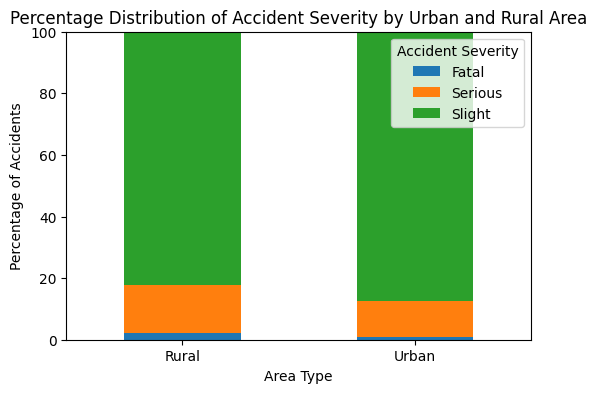

In [ ]:
urban_rural_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(6, 4)
)
plt.title("Percentage Distribution of Accident Severity by Urban and Rural Area")
plt.xlabel("Area Type")
plt.ylabel("Percentage of Accidents")
plt.legend(title="Accident Severity")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.show()

- Urban areas have a higher proportion of Slight accidents, whereas Rural areas have relatively higher proportions of Fatal and Serious accidents. This indicates an association between the type of area (Urban/Rural) and accident severity.

In [ ]:
pd.crosstab(df[ 'Weather_Conditions'],df["Accident_Severity"],normalize="index")*100

Accident_Severity,Fatal,Serious,Slight
Weather_Conditions,,,
Fine + high winds,1.778907,13.691233,84.529860
Fine no high winds,1.336698,13.764556,84.898746
Fog or mist,1.775148,13.372781,84.852071
Other,0.954329,10.270393,88.775278
Raining + high winds,1.418842,12.485812,86.095346
Raining no high winds,1.086770,11.776682,87.136549
Snowing + high winds,0.185874,11.338290,88.475836
Snowing no high winds,0.640628,8.638148,90.721223
Unknown,0.891530,8.238402,90.870068


- Slight accidents are the majority under every weather condition, ranging from approximately 84.5% to 90.9%.
- The highest proportion of Fatal accidents appears under Fine + high winds (1.78%) and Fog or mist (1.78%). The difference between them is very small.
- Fine weather without high winds has a relatively high Serious accident proportion (13.76%).
- Fog or mist also shows a relatively high Fatal accident proportion, which could be worth mentioning as an association, but don't claim causation.
- Weather conditions such as Snowing + high winds have a very low Fatal percentage, but you should first check their raw sample sizes before interpreting this strongly.

In [ ]:
df.columns

Index(['Accident_Index', 'Accident Date', 'Day_of_Week', 'Junction_Control',
       'Junction_Detail', 'Accident_Severity', 'Latitude', 'Light_Conditions',
       'Local_Authority_(District)', 'Carriageway_Hazards', 'Longitude',
       'Number_of_Casualties', 'Number_of_Vehicles', 'Police_Force',
       'Road_Surface_Conditions', 'Road_Type', 'Speed_limit', 'Time',
       'Urban_or_Rural_Area', 'Weather_Conditions', 'Vehicle_Type', 'Month',
       'Year', 'Day_Type', 'Latitude_Range', 'Longitude_Range',
       'Casualty_Range', 'Hour'],
      dtype='object')

In [ ]:
vehicle_pct = pd.crosstab(
    df["Vehicle_Type"],
    df["Accident_Severity"],
    normalize="index"
) * 100

vehicle_pct

Accident_Severity,Fatal,Serious,Slight
Vehicle_Type,,,
Agricultural vehicle,1.068091,14.018692,84.913218
Bus or coach (17 or more pass seats),0.990099,13.067004,85.942897
Car,1.306197,13.170823,85.522979
Goods 7.5 tonnes mgw and over,1.025720,13.441519,85.532762
Goods over 3.5t. and under 7.5t,1.239009,14.068745,84.692246
Minibus (8 - 16 passenger seats),1.218027,14.372716,84.409257
Motorcycle 125cc and under,1.182137,13.514302,85.303561
Motorcycle 50cc and under,1.161221,13.529571,85.309209
Motorcycle over 125cc and up to 500cc,1.491629,12.602740,85.905632


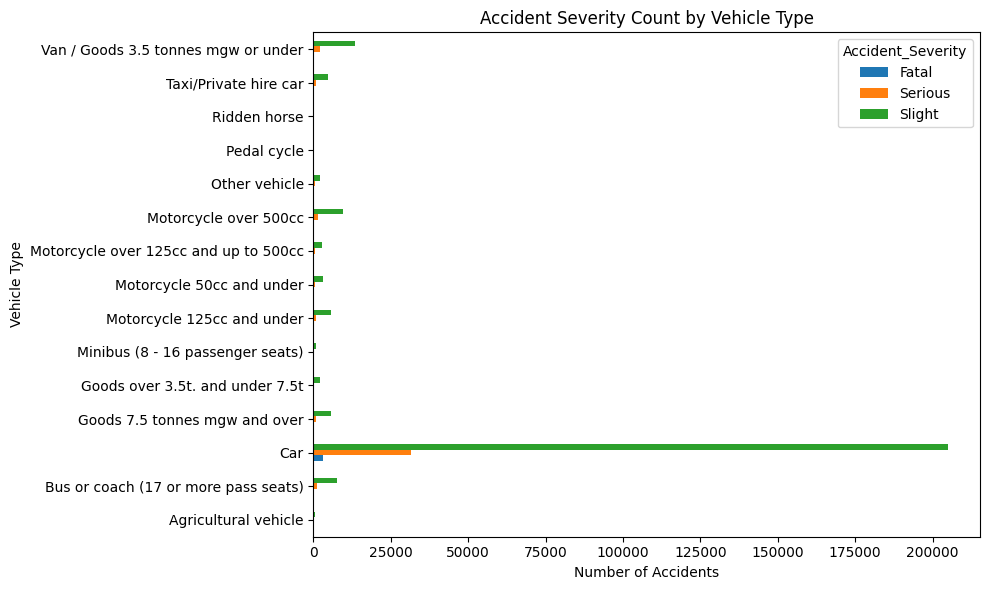

In [ ]:
vehicle_counts = pd.crosstab(
    df["Vehicle_Type"],
    df["Accident_Severity"]
)

vehicle_counts.plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Accident Severity Count by Vehicle Type")
plt.xlabel("Number of Accidents")
plt.ylabel("Vehicle Type")
plt.tight_layout()
plt.show()

- Cars account for the highest number of accidents across all severity categories. However, this may partly reflect the higher number of cars on the road and in the dataset.
- Slight accidents are the most common outcome for every major vehicle type.
- Among the motorcycle categories, motorcycles over 500cc have a noticeable number of Fatal and Serious accidents, making vehicle type a potentially meaningful factor associated with accident severity.
- Larger vehicles such as buses/coaches and goods vehicles also show substantial numbers of Serious accidents, although their total accident counts are much lower than cars.
- Some categories, such as Ridden horse and Pedal cycle, have very few observations, so strong conclusions should not be drawn from their raw counts.

## MULTIVARIATE ANALYSIS

In [ ]:

pd.crosstab(
    [df["Hour"], df["Urban_or_Rural_Area"]],
    df["Accident_Severity"],
    normalize="index"
) * 100

Accident_Severity            Fatal    Serious     Slight
Hour Urban_or_Rural_Area                                
0    Rural                4.490501  20.552677  74.956822
     Urban                2.354949  16.791809  80.853242
1    Rural                5.388761  21.324095  73.287144
     Urban                2.193375  16.293644  81.512981
2    Rural                5.864811  20.477137  73.658052
     Urban                2.551640  19.623329  77.825030
3    Rural                4.886364  21.363636  73.750000
     Urban                2.655486  18.448637  78.895877
4    Rural                4.227213  21.532365  74.240423
     Urban                3.215768  19.502075  77.282158
5    Rural                5.231037  17.436792  77.332171
     Urban                1.860119  16.666667  81.473214
6    Rural                3.110929  16.291445  80.597626
     Urban                1.377605  13.740728  84.881667
7    Rural                2.026542  13.737446  84.236011
     Urban                0.715922  12.227950  87.056128
8    Rural                1.110061  11.195087  87.694851
     Urban                0.482817  10.139165  89.378018
9    Rural                1.647100  11.932714  86.420186
     Urban                0.862681  10.524713  88.612605
10   Rural                2.068032  14.843448  83.088520
     Urban                0.800743  10.398050  88.801207
11   Rural                1.965967  15.397324  82.636709
     Urban                0.654243  10.408406  88.937351
12   Rural                1.498764  14.678616  83.822621
     Urban                0.522325  10.227464  89.250211
13   Rural                1.742483  16.052429  82.205089
     Urban                0.704789  10.619894  88.675316
14   Rural                1.784643  16.466707  81.748650
     Urban                0.782321  10.936366  88.281313
15   Rural                1.732966  15.806748  82.460286
     Urban                0.508044  11.691061  87.800895
16   Rural                1.874854  15.678463  82.446684
     Urban                0.665934  11.528592  87.805474
17   Rural                1.606642  15.311624  83.081734
     Urban                0.650085  11.464104  87.885811
18   Rural                1.894893  16.269430  81.835677
     Urban                0.615041  12.258876  87.126083
19   Rural                2.435161  17.620273  79.944565
     Urban                0.648148  12.212963  87.138889
20   Rural                2.719113  18.796199  78.484688
     Urban                0.840557  13.343840  85.815603
21   Rural                3.398653  17.238212  79.363135
     Urban                1.117047  13.242674  85.640278
22   Rural                2.719239  19.748470  77.532291
     Urban                1.345119  14.488855  84.166026
23   Rural                3.819742  19.141631  77.038627
     Urban                1.400491  14.692875  83.906634

- Rural areas consistently have a higher percentage of Fatal accidents than Urban areas across most hours.
- The highest proportion of Fatal accidents occurs in Rural areas around 2 AM (5.86%).
- Late-night and early-morning hours (approximately 12 AM–5 AM) show relatively higher proportions of both Fatal and Serious accidents, especially in Rural areas.
- Rural areas generally have a higher proportion of Serious accidents compared with Urban areas throughout the day.
- Urban areas consistently have a higher proportion of Slight accidents, often around 84–89%.
- The difference between Rural and Urban severity distributions remains visible during both daytime and nighttime.
- Overall, accident severity appears to be associated with both the Hour of occurrence and whether the accident occurs in an Urban or Rural area.

In [ ]:

pd.crosstab(
    [df["Speed_limit"], df["Urban_or_Rural_Area"]],
    df["Accident_Severity"],
    normalize="index"
) * 100

Accident_Severity                   Fatal    Serious      Slight
Speed_limit Urban_or_Rural_Area                                 
10          Rural                0.000000   0.000000  100.000000
15          Urban                0.000000   0.000000  100.000000
20          Rural                0.293255  12.316716   87.390029
            Urban                0.508210  13.096169   86.395622
30          Rural                0.813657  13.124976   86.061366
            Urban                0.761527  11.871295   87.367179
40          Rural                1.778976  14.312668   83.908356
            Urban                1.170799  11.721763   87.107438
50          Rural                2.470007  15.765702   81.764291
            Urban                1.449275  11.175523   87.375201
60          Rural                2.881484  19.088719   78.029796
            Urban                1.060071  12.973246   85.966683
70          Rural                2.376970  12.482895   85.140135
            Urban                1.216730   9.391635   89.391635

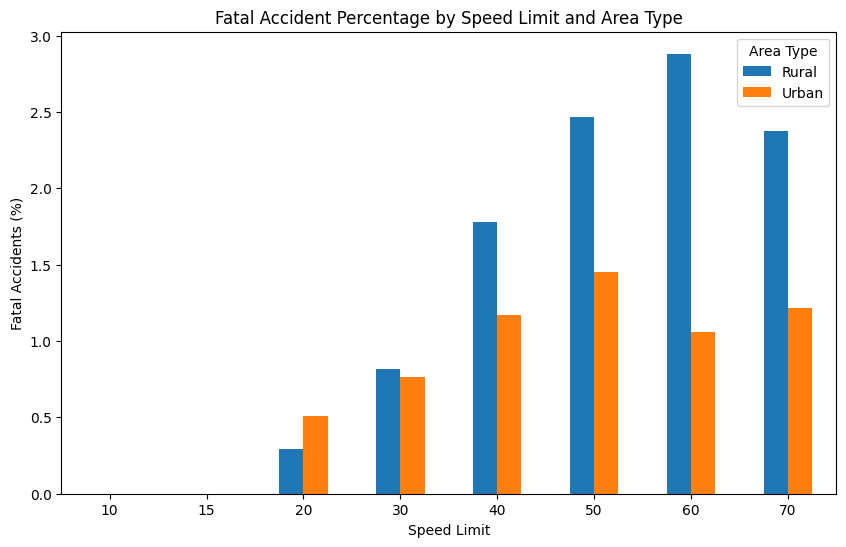

In [ ]:
severity_multi = pd.crosstab(
    [df["Speed_limit"], df["Urban_or_Rural_Area"]],
    df["Accident_Severity"],
    normalize="index"
) * 100

fatal = severity_multi["Fatal"].unstack()

fatal.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Fatal Accident Percentage by Speed Limit and Area Type")
plt.xlabel("Speed Limit")
plt.ylabel("Fatal Accidents (%)")
plt.legend(title="Area Type")
plt.xticks(rotation=0)
plt.show()

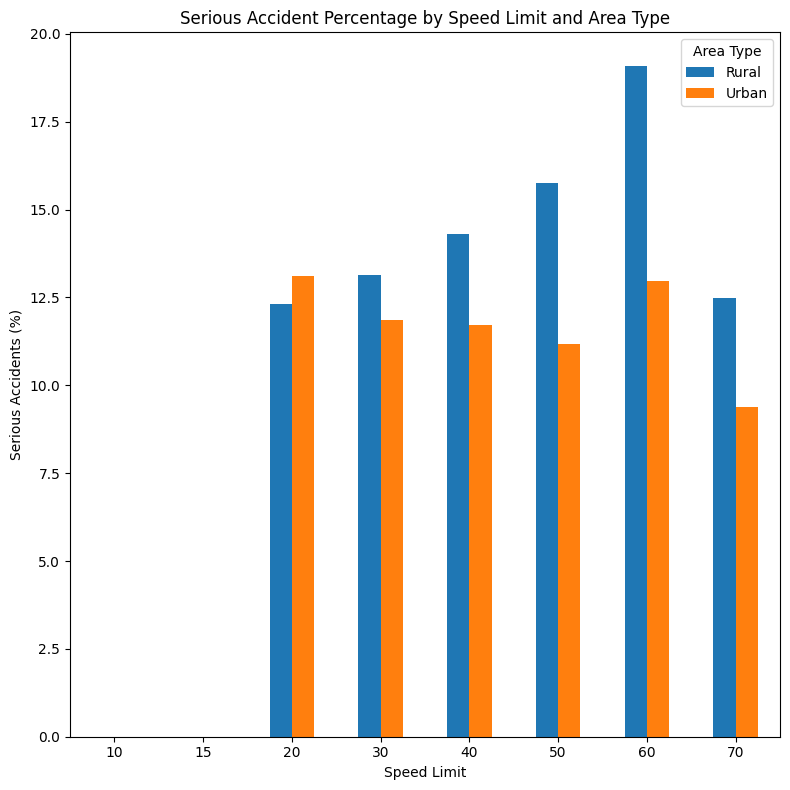

In [ ]:

serious = severity_multi["Serious"].unstack()

serious.plot(
    kind="bar",
    figsize=(8, 8)
)

plt.title("Serious Accident Percentage by Speed Limit and Area Type")
plt.xlabel("Speed Limit")
plt.ylabel("Serious Accidents (%)")
plt.legend(title="Area Type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

- The proportion of Fatal accidents generally increases in Rural areas as the speed limit increases from 20 to 60.
- Rural areas show higher percentages of Fatal accidents than Urban areas at speed limits from 40 to 70.
- At a speed limit of 60, Rural areas have the highest proportion of both Fatal (2.88%) and Serious (19.09%) accidents.
- At higher speed limits (40–60), the difference in severity between Rural and Urban areas becomes more noticeable.
- Urban areas generally have a higher proportion of Slight accidents across most speed limits.
- The results suggest an association between Speed Limit, Area Type, and - Accident Severity, with higher speed limits in Rural areas being associated with relatively more severe accident outcomes.
- The 10 and 15 speed-limit categories should be interpreted cautiously because they may contain very few observations.

## EDA FINDINGS

1. The dataset covers 307,973 road accidents across 21 features (2021–2022), combining time, location, road, weather, and vehicle attributes.
2. Data was reasonably clean — only Carriageway_Hazards had major missingness; all gaps were resolved by dropping 17 rows and labeling the rest "Unknown."
3. Accident severity is heavily imbalanced: Slight (263,265) ≫ Serious (40,738) ≫ Fatal (3,953) — a key constraint for the ML stage.
4. Accidents are not evenly spread geographically — they cluster in specific latitude/longitude bands, with Birmingham, Leeds, and Manchester recording the most.
5. Time patterns are clear: accidents peak at 5 PM (commute hour) and on Saturdays, and are lowest around 4 AM; 2021 had notably more accidents than 2022.
6. Most accidents happen under "normal" conditions — daylight, fine weather, dry roads, urban areas — but this mainly reflects higher exposure (more driving happens then), not necessarily higher risk.
7. Speed limit is one of the strongest predictors of severity: Serious/Fatal share rises steadily from ~20 mph upward, peaking around 60 mph.
8. Area type matters a lot: Urban areas have a higher share of Slight accidents, while Rural areas have consistently higher Fatal/Serious shares.
9. Rural + high speed limit together is the worst combination— at 60 mph in rural areas, Fatal (2.88%) and Serious (19.09%) rates are at their highest.
10. Time of day interacts with area type: late-night/early-morning hours (12 AM–5 AM), especially in rural areas, show sharply elevated Fatal rates, peaking near 2 AM (~5.86% in rural areas).
11. Most accidents involve just one casualty and one or two vehicles, with a strong right-skew toward low-casualty events.
12. Cars dominate accident volume, but motorcycles over 500cc show a disproportionately high Fatal/Serious share relative to their numbers — flagging vehicle type as a meaningful severity factor.
13. District-level severity doesn't track with volume — Birmingham has the most accidents overall, but Westminster has more Fatal accidents, and Ryedale has the highest Serious-accident rate (~31%).
14. Weather and road-surface effects on severity are present but weaker — fog/mist and flooded roads show slightly elevated Fatal shares, though sample sizes there are small.
15. Overall, Speed Limit, Area Type, and Hour of Day emerge as the strongest and most consistent factors linked to accident severity, making them priority features for the accident-severity prediction model.


## feature Engineering

In [ ]:

df.columns

Index(['Accident_Index', 'Accident Date', 'Day_of_Week', 'Junction_Control',
       'Junction_Detail', 'Accident_Severity', 'Latitude', 'Light_Conditions',
       'Local_Authority_(District)', 'Carriageway_Hazards', 'Longitude',
       'Number_of_Casualties', 'Number_of_Vehicles', 'Police_Force',
       'Road_Surface_Conditions', 'Road_Type', 'Speed_limit', 'Time',
       'Urban_or_Rural_Area', 'Weather_Conditions', 'Vehicle_Type', 'Month',
       'Year', 'Day_Type', 'Latitude_Range', 'Longitude_Range',
       'Casualty_Range', 'Hour'],
      dtype='object')

In [ ]:
X=df.drop(columns=["Accident_Index",'Junction_Detail',"Day_Type","Junction_Control","Accident Date","Accident_Severity","Latitude","Carriageway_Hazards","Longitude","Casualty_Range","Time","Year","Number_of_Vehicles","Number_of_Casualties",'Latitude_Range', 'Longitude_Range',"Police_Force"])
y=df["Accident_Severity"]

In [ ]:

X.shape

(307955, 11)

In [ ]:
X.columns

Index(['Day_of_Week', 'Light_Conditions', 'Local_Authority_(District)',
       'Road_Surface_Conditions', 'Road_Type', 'Speed_limit',
       'Urban_or_Rural_Area', 'Weather_Conditions', 'Vehicle_Type', 'Month',
       'Hour'],
      dtype='object')

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

In [ ]:
#Train test split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42, stratify=y)

In [ ]:
cat_cols = [
    'Day_of_Week',
    'Light_Conditions',
    'Local_Authority_(District)',
    'Road_Surface_Conditions',
    'Road_Type',
    'Urban_or_Rural_Area',
    'Weather_Conditions',
    'Vehicle_Type',
    'Month'
]

num_cols = [
    'Speed_limit',

    'Hour'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
        ('num', StandardScaler(), num_cols)
    ]
)

In [ ]:
le = LabelEncoder()

y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

## MODELLING

In [ ]:
#logistic Regression
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

pipe_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

In [ ]:
pipe_lr.fit(X_train, y_train_encoded)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Day_of_Week',
                                                   'Light_Conditions',
                                                   'Local_Authority_(District)',
                                                   'Road_Surface_Conditions',
                                                   'Road_Type',
                                                   'Urban_or_Rural_Area',
                                                   'Weather_Conditions',
                                                   'Vehicle_Type', 'Month']),
                                                 ('num', StandardScaler(),
                                                  ['Speed_limit', 'Hour'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [ ]:
y_pred=pipe_lr.predict(X_test)
y_pred

array([2, 1, 2, ..., 2, 1, 2])

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test_encoded, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.49629004237632124


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test_encoded,
    y_pred,
    target_names=le.classes_
))

              precision    recall  f1-score   support

       Fatal       0.03      0.54      0.06       790
     Serious       0.16      0.32      0.21      8148
      Slight       0.89      0.52      0.66     52653

    accuracy                           0.50     61591
   macro avg       0.36      0.46      0.31     61591
weighted avg       0.78      0.50      0.59     61591



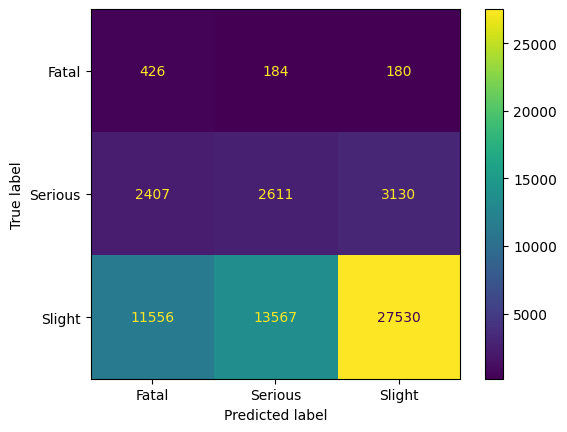

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_encoded, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le.classes_
)

disp.plot()
plt.show()

In [ ]:
#Decision Tree
from sklearn.tree import DecisionTreeClassifier
pipedt = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', DecisionTreeClassifier(
            criterion='entropy',
            max_depth=10,
            min_samples_split=10,
            min_samples_leaf=5,
            class_weight='balanced',
            random_state=42
        ))
    ]
)


In [ ]:
pipedt.fit(X_train, y_train_encoded)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Day_of_Week',
                                                   'Light_Conditions',
                                                   'Local_Authority_(District)',
                                                   'Road_Surface_Conditions',
                                                   'Road_Type',
                                                   'Urban_or_Rural_Area',
                                                   'Weather_Conditions',
                                                   'Vehicle_Type', 'Month']),
                                                 ('num', StandardScaler(),
                                                  ['Speed_limit', 'Hour'])])),
                ('classifier',
                 DecisionTreeClassifier(class_weight='balanced',
                                        criterion='entropy', max_depth=10,
                                        min_samples_leaf=5,
                                        min_samples_split=10,
                                        random_state=42))])

In [ ]:
y_pred1=pipedt.predict(X_test)
y_pred1

array([2, 2, 0, ..., 2, 2, 2])

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test_encoded, y_pred1)

print("Accuracy:", accuracy)

Accuracy: 0.5967430306375932


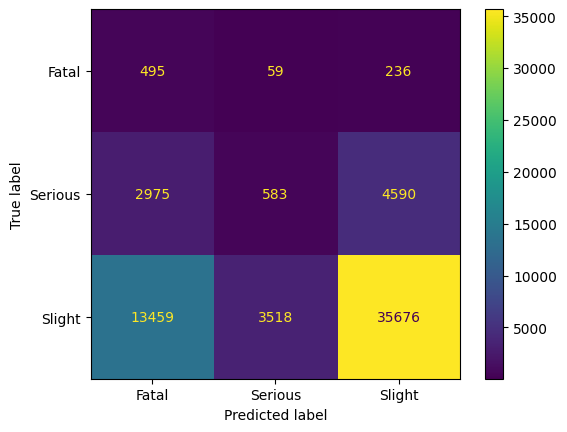

In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_encoded, y_pred1)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le.classes_
)

disp.plot()
plt.show()

In [ ]:
#RandomForest
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score

piperf2 = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=500,
        max_depth=30,              # was 10 — this is the main change
        min_samples_split=5,       # was 10
        min_samples_leaf=2,        # was 5
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    ))
])

piperf2.fit(X_train, y_train_encoded)
y_pred3 = piperf2.predict(X_test)

print("Accuracy:", accuracy_score(y_test_encoded, y_pred3))
print("Macro F1:", f1_score(y_test_encoded, y_pred3, average='macro'))
print(classification_report(y_test_encoded, y_pred3, target_names=le.classes_))

Accuracy: 0.6504684125927489
Macro F1: 0.34694862955805233
              precision    recall  f1-score   support

       Fatal       0.04      0.46      0.07       790
     Serious       0.16      0.18      0.17      8148
      Slight       0.88      0.73      0.80     52653

    accuracy                           0.65     61591
   macro avg       0.36      0.46      0.35     61591
weighted avg       0.78      0.65      0.70     61591



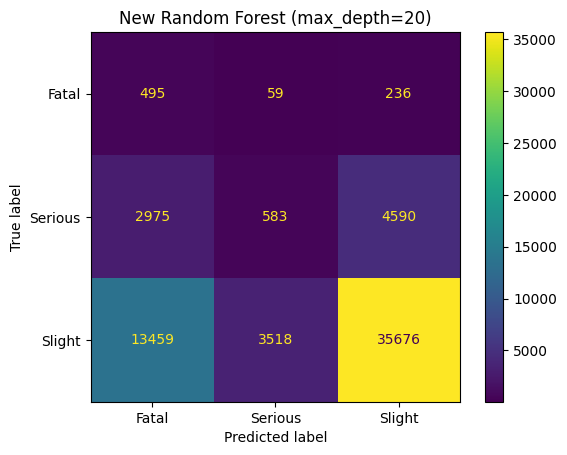

In [ ]:
lcm = confusion_matrix(y_test_encoded, y_pred3)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(values_format='d')
plt.title("New Random Forest (max_depth=20)")
plt.show()

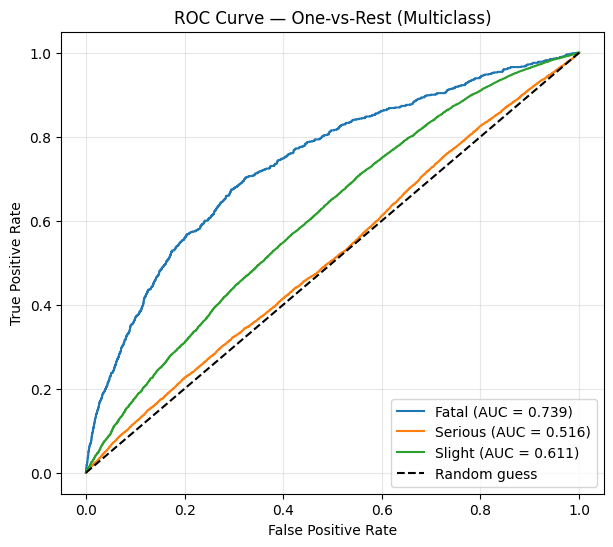

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

classes = le.classes_  # e.g. ['Fatal', 'Serious', 'Slight']
y_test_bin = label_binarize(y_test, classes=classes)

probs_multi = piperf2.predict_proba(X_test)  # <-- replace with your actual fitted multiclass model

plt.figure(figsize=(7,6))
for i, cls in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], probs_multi[:, i])
    auc_score = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{cls} (AUC = {auc_score:.3f})')

plt.plot([0,1], [0,1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — One-vs-Rest (Multiclass)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

In [ ]:
print(y_train.value_counts())

Accident_Severity
Slight     210611
Serious     32590
Fatal        3163
Name: count, dtype: int64


In [ ]:

#Simple XG BOOST
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder

# Encode target labels
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

xgb_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', XGBClassifier(
            n_estimators=200,
            max_depth=6,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            objective='multi:softmax',
            num_class=3,
            eval_metric='mlogloss',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

xgb_pipeline.fit(X_train, y_train_encoded)

y_pred_xgb = xgb_pipeline.predict(X_test)

print("Accuracy:", accuracy_score(y_test_encoded, y_pred_xgb))
print("Macro F1:", f1_score(y_test_encoded, y_pred_xgb, average='macro'))

print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    y_pred_xgb,
    target_names=label_encoder.classes_
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_encoded, y_pred_xgb))

Accuracy: 0.8548164504554236
Macro F1: 0.31235174329554594

Classification Report:
              precision    recall  f1-score   support

       Fatal       0.32      0.01      0.01       790
     Serious       0.67      0.00      0.00      8148
      Slight       0.85      1.00      0.92     52653

    accuracy                           0.85     61591
   macro avg       0.61      0.34      0.31     61591
weighted avg       0.82      0.85      0.79     61591


Confusion Matrix:
[[    6     0   784]
 [    2     2  8144]
 [   11     1 52641]]


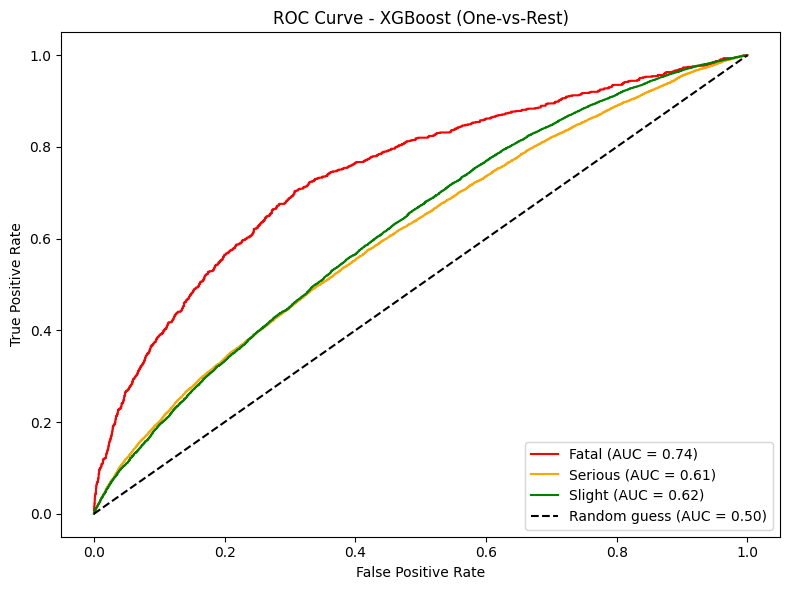

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

# Binarize the true labels: one column per class (0/1)
y_test_bin = label_binarize(y_test_encoded, classes=[0, 1, 2])  # Fatal, Serious, Slight

# Get predicted probabilities from your final model
y_score = xgb_pipeline.predict_proba(X_test)

# Compute ROC curve and AUC for each class
plt.figure(figsize=(8, 6))
colors = ['red', 'orange', 'green']

for i, class_name in enumerate(le.classes_):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[i], label=f'{class_name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random guess (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - XGBoost (One-vs-Rest)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
#Balanced XG boost
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print(label_encoder.classes_)

['Fatal' 'Serious' 'Slight']


In [ ]:

sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train_encoded
)

In [ ]:
xgb_balanced = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', XGBClassifier(
            n_estimators=200,
            max_depth=6,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            objective='multi:softmax',
            num_class=3,
            eval_metric='mlogloss',
            random_state=42,
            n_jobs=-1
        ))
    ]
)

xgb_balanced.fit(
    X_train,
    y_train_encoded,
    model__sample_weight=sample_weights
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Day_of_Week',
                                                   'Light_Conditions',
                                                   'Local_Authority_(District)',
                                                   'Road_Surface_Conditions',
                                                   'Road_Type',
                                                   'Urban_or_Rural_Area',
                                                   'Weather_Conditions',
                                                   'Vehicle_Type', 'Month']),
                                                 ('num', StandardScaler(),
                                                  ['Speed_limit', 'Hour'])])),
                ('model',
                 XGBClassifi...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=6, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=-1, num_class=3, ...))])

In [ ]:
y_pred_xgb_balanced = xgb_balanced.predict(X_test)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test_encoded, y_pred_xgb_balanced))

print("Macro F1:", f1_score(
    y_test_encoded,
    y_pred_xgb_balanced,
    average='macro'
))

print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    y_pred_xgb_balanced,
    target_names=label_encoder.classes_
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test_encoded,
    y_pred_xgb_balanced
))

Accuracy: 0.5686707473494504
Macro F1: 0.3279208628478686

Classification Report:
              precision    recall  f1-score   support

       Fatal       0.03      0.56      0.06       790
     Serious       0.16      0.23      0.19      8148
      Slight       0.89      0.62      0.73     52653

    accuracy                           0.57     61591
   macro avg       0.36      0.47      0.33     61591
weighted avg       0.78      0.57      0.65     61591


Confusion Matrix:
[[  440   128   222]
 [ 2419  1851  3878]
 [10607  9312 32734]]


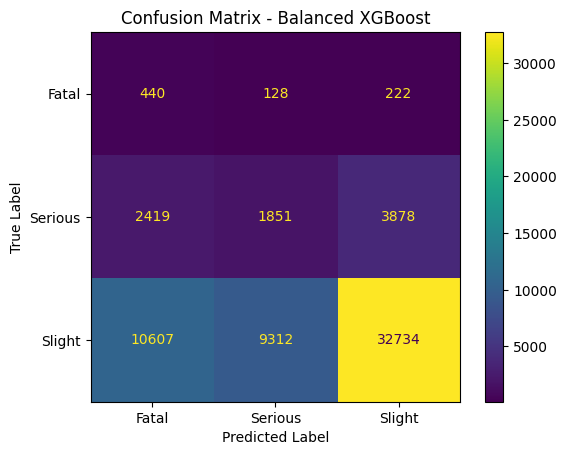

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test_encoded,
    y_pred_xgb_balanced
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(values_format='d')

plt.title("Confusion Matrix - Balanced XGBoost")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

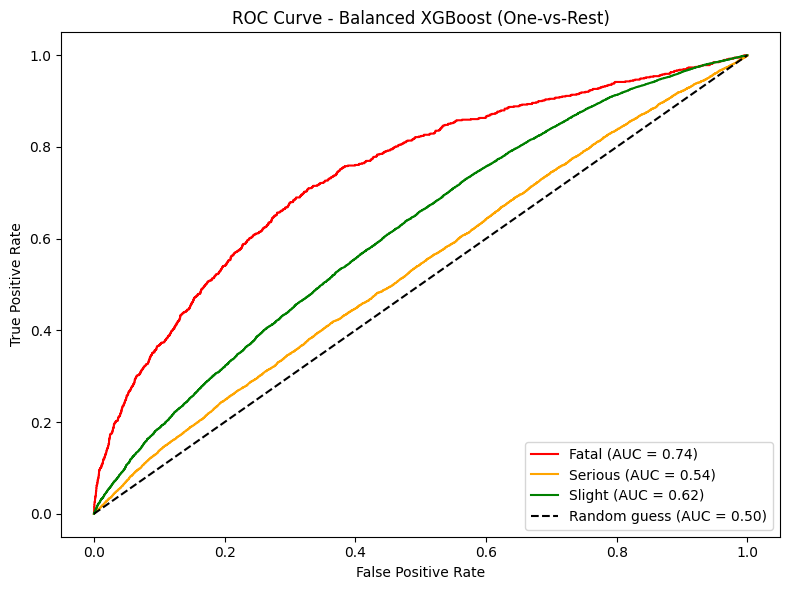

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
import numpy as np

# Binarize the true labels: one column per class (0/1)
y_test_bin = label_binarize(y_test_encoded, classes=[0, 1, 2])  # Fatal, Serious, Slight

# Get predicted probabilities from your final model
y_score = xgb_balanced.predict_proba(X_test)

# Compute ROC curve and AUC for each class
plt.figure(figsize=(8, 6))
colors = ['red', 'orange', 'green']

for i, class_name in enumerate(le.classes_):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[i], label=f'{class_name} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random guess (AUC = 0.50)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Balanced XGBoost (One-vs-Rest)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score

macro_auc = roc_auc_score(y_test_bin, y_score, average='macro', multi_class='ovr')
weighted_auc = roc_auc_score(y_test_bin, y_score, average='weighted', multi_class='ovr')

print("Macro ROC-AUC:", macro_auc)
print("Weighted ROC-AUC:", weighted_auc)

Macro ROC-AUC: 0.6316141161666519
Weighted ROC-AUC: 0.6074091839644143


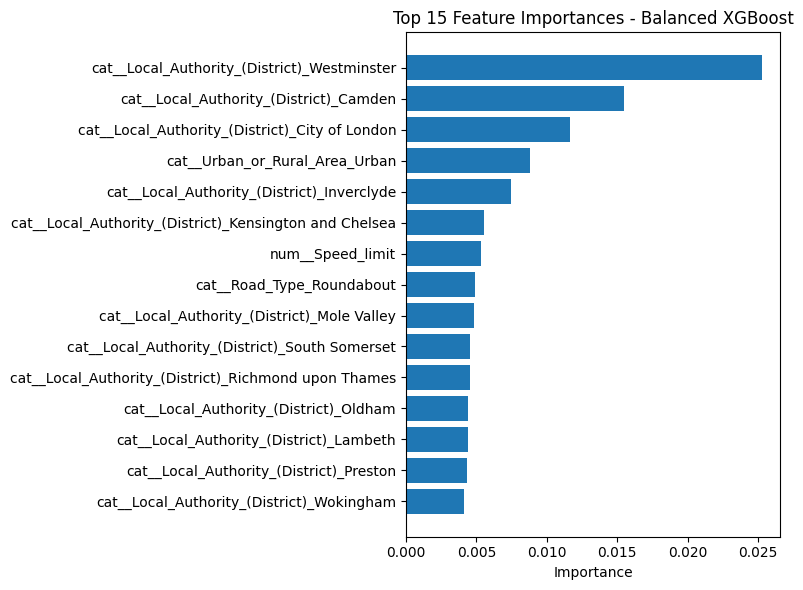

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Get feature names after one-hot encoding
feature_names = xgb_balanced.named_steps['preprocessor'].get_feature_names_out()

# Get importances from the trained XGBoost model
importances = xgb_balanced.named_steps['model'].feature_importances_

# Sort and take top 15
indices = np.argsort(importances)[-15:]

plt.figure(figsize=(8, 6))
plt.barh(range(len(indices)), importances[indices])
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Importance")
plt.title("Top 15 Feature Importances - Balanced XGBoost")
plt.tight_layout()
plt.show()

Local_Authority_(District)    0.903939
Month                         0.014996
Road_Type                     0.014109
Vehicle_Type                  0.013366
Weather_Conditions            0.012431
Urban_or_Rural_Area           0.012010
Road_Surface_Conditions       0.008301
Light_Conditions              0.007888
Day_of_Week                   0.006020
Speed_limit                   0.005290
Hour                          0.001650
dtype: float32


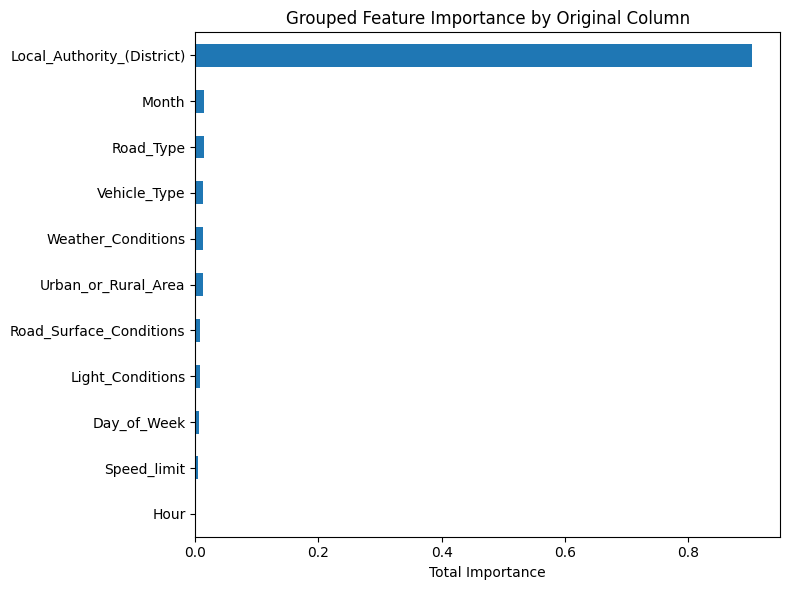

In [ ]:
import pandas as pd

# Map each encoded feature back to its original column
importance_df = pd.DataFrame({'feature': feature_names, 'importance': importances})
importance_df['original_feature'] = importance_df['feature'].str.extract(r'(?:cat__|num__)([^_]+(?:_[^_]+)*?)(?:_[^_]+)?$')

# Simpler and more reliable: group by prefix before one-hot split
grouped = {}
for col in cat_cols + num_cols:
    mask = importance_df['feature'].str.contains(col, regex=False)
    grouped[col] = importance_df.loc[mask, 'importance'].sum()

grouped_df = pd.Series(grouped).sort_values(ascending=False)
print(grouped_df)

grouped_df.plot(kind='barh', figsize=(8,6))
plt.title("Grouped Feature Importance by Original Column")
plt.xlabel("Total Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Local_Authority_(District)    0.014294
Road_Type                     0.006417
Hour                          0.004479
Road_Surface_Conditions       0.002938
Month                         0.001765
Day_of_Week                   0.000988
Weather_Conditions            0.000425
Vehicle_Type                  0.000135
Light_Conditions             -0.001504
Speed_limit                  -0.006584
Urban_or_Rural_Area          -0.009295
dtype: float64


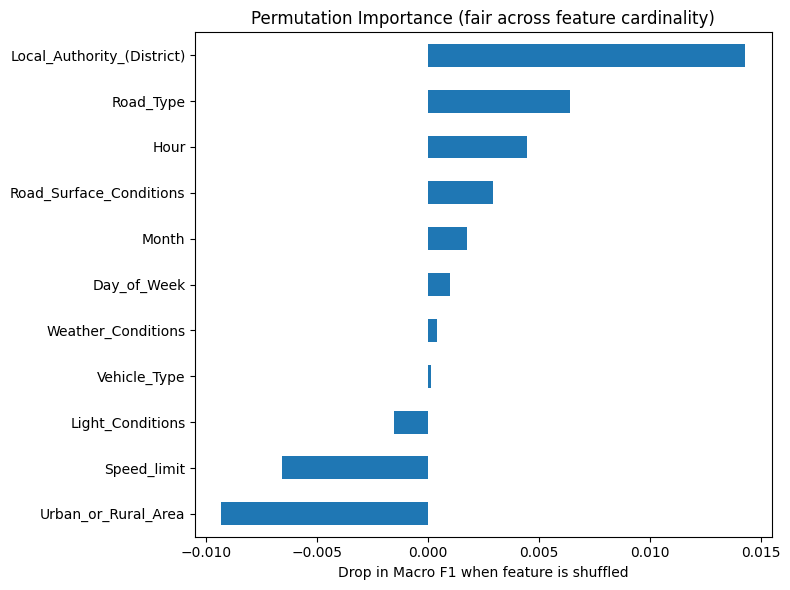

In [ ]:
from sklearn.inspection import permutation_importance
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Sample by position, not by DataFrame index
np.random.seed(42)
sample_pos = np.random.choice(len(X_test), size=10000, replace=False)

X_test_sample = X_test.iloc[sample_pos]
y_test_sample = y_test_encoded[sample_pos]

result = permutation_importance(
    xgb_balanced, X_test_sample, y_test_sample,
    n_repeats=5, random_state=42, n_jobs=-1, scoring='f1_macro'
)

perm_df = pd.Series(result.importances_mean, index=X.columns).sort_values(ascending=False)
print(perm_df)

perm_df.plot(kind='barh', figsize=(8,6))
plt.title("Permutation Importance (fair across feature cardinality)")
plt.xlabel("Drop in Macro F1 when feature is shuffled")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [ ]:
from lightgbm import LGBMClassifier

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LGBMClassifier(
        objective='multiclass',
        num_class=3,
        class_weight='balanced',
        max_depth=8,
        learning_rate=0.05,
        num_leaves=63,
        n_estimators=500,
        random_state=42,
        verbosity=-1
    ))
])

pipeline.fit(X_train, y_train_encoded)

preds = pipeline.predict(X_test)

from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix
print("Accuracy:", accuracy_score(y_test_encoded, preds))
print("Balanced accuracy:", balanced_accuracy_score(y_test_encoded, preds))
print("Macro-F1:", f1_score(y_test_encoded, preds, average='macro'))
print(classification_report(y_test_encoded, preds))
print(confusion_matrix(y_test_encoded, preds))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Accuracy: 0.5655371726388596
Balanced accuracy: 0.4556206565676308
Macro-F1: 0.3308394284481631
              precision    recall  f1-score   support

           0       0.03      0.47      0.06       790
           1       0.16      0.28      0.21      8148
           2       0.89      0.61      0.72     52653

    accuracy                           0.57     61591
   macro avg       0.36      0.46      0.33     61591
weighted avg       0.78      0.57      0.65     61591

[[  373   191   226]
 [ 2020  2316  3812]
 [ 8671 11839 32143]]


In [ ]:
#random Forest with Smote and 5fold Cv
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report

# ---- 1. Features & target ----
features = [
    'Day_of_Week', 'Light_Conditions', 'Local_Authority_(District)',
    'Road_Surface_Conditions', 'Road_Type', 'Speed_limit',
    'Urban_or_Rural_Area', 'Weather_Conditions', 'Vehicle_Type',
    'Month', 'Hour'
]
cat_cols = [c for c in features if df[c].dtype == 'object']

X = df[features]
y = df["Accident_Severity"]

# ---- 2. Reduce dataset size to avoid the earlier memory crash ----
X_sample = X.sample(n=100000, random_state=42)
y_sample = y.loc[X_sample.index]

# ---- 3. Preprocessing ----
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
    ],
    remainder='passthrough'
)

# ---- 4. Random Forest, lighter than before (memory-safe) ----
rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=30,          # capped depth — unlimited depth is what likely blew up memory
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# ---- 5. Full SMOTE balancing restored (no sampling_strategy cap) ----
pipeline = ImbPipeline(steps=[
    ('preprocess', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('model', rf)
])

# ---- 6. Fewer folds, sequential (not parallel) to stay within memory ----
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'macro_f1': 'f1_macro', 'recall_macro': 'recall_macro'}

cv_results = cross_validate(
    pipeline, X_sample, y_sample, cv=cv, scoring=scoring,
    n_jobs=1   # sequential folds — critical, avoid -1 here
)

print(f"Accuracy    : {cv_results['test_accuracy'].mean():.3f} ± {cv_results['test_accuracy'].std():.3f}")
print(f"Macro F1    : {cv_results['test_macro_f1'].mean():.3f} ± {cv_results['test_macro_f1'].std():.3f}")
print(f"Macro Recall: {cv_results['test_recall_macro'].mean():.3f} ± {cv_results['test_recall_macro'].std():.3f}")

# ---- 7. Per-class recall ----
fold_reports = []
for train_idx, val_idx in cv.split(X_sample, y_sample):
    X_train, X_val = X_sample.iloc[train_idx], X_sample.iloc[val_idx]
    y_train, y_val = y_sample.iloc[train_idx], y_sample.iloc[val_idx]
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_val)
    fold_reports.append(classification_report(y_val, y_pred, output_dict=True))

for cls in ['Fatal', 'Serious', 'Slight']:
    recalls = [r[cls]['recall'] for r in fold_reports if cls in r]
    print(f"{cls} avg recall: {np.mean(recalls):.3f} ± {np.std(recalls):.3f}")

Accuracy    : 0.834 ± 0.001
Macro F1    : 0.339 ± 0.002
Macro Recall: 0.345 ± 0.001
Fatal avg recall: 0.018 ± 0.004
Serious avg recall: 0.051 ± 0.001
Slight avg recall: 0.966 ± 0.001


In [ ]:
#Rando Forest with Class weight
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

features = [
    'Day_of_Week', 'Light_Conditions', 'Local_Authority_(District)',
    'Road_Surface_Conditions', 'Road_Type', 'Speed_limit',
    'Urban_or_Rural_Area', 'Weather_Conditions', 'Vehicle_Type',
    'Month', 'Hour'
]
cat_cols = [c for c in features if df[c].dtype == 'object']

X = df[features]
y = df["Accident_Severity"]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
    ],
    remainder='passthrough'
)
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=30,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

pipeline = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('model', rf)
])

# ---- 4. Stratified 5-fold CV (proper validation this time) ----
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'accuracy': 'accuracy', 'macro_f1': 'f1_macro', 'recall_macro': 'recall_macro'}

cv_results = cross_validate(pipeline, X, y, cv=cv, scoring=scoring, n_jobs=-1)

print(f"Accuracy    : {cv_results['test_accuracy'].mean():.3f} ± {cv_results['test_accuracy'].std():.3f}")
print(f"Macro F1    : {cv_results['test_macro_f1'].mean():.3f} ± {cv_results['test_macro_f1'].std():.3f}")
print(f"Macro Recall: {cv_results['test_recall_macro'].mean():.3f} ± {cv_results['test_recall_macro'].std():.3f}")

# ---- 5. Per-class recall across folds ----
fold_reports = []
for train_idx, val_idx in cv.split(X, y):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_val)
    fold_reports.append(classification_report(y_val, y_pred, output_dict=True))

for cls in ['Fatal', 'Serious', 'Slight']:
    recalls = [r[cls]['recall'] for r in fold_reports if cls in r]
    print(f"{cls} avg recall: {np.mean(recalls):.3f} ± {np.std(recalls):.3f}")

# ---- 6. Fit on full data and save for the dashboard ----
pipeline.fit(X, y)
import pickle
with open('severity_rf_model.pkl', 'wb') as f:
    pickle.dump(pipeline, f)

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Accuracy    : 0.817 ± 0.001
Macro F1    : 0.358 ± 0.002
Macro Recall: 0.356 ± 0.002
Fatal avg recall: 0.040 ± 0.005
Serious avg recall: 0.086 ± 0.003
Slight avg recall: 0.942 ± 0.001


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Macro AUC   : 0.609
Weighted AUC: 0.577
Fatal AUC: 0.693
Serious AUC: 0.554
Slight AUC: 0.579


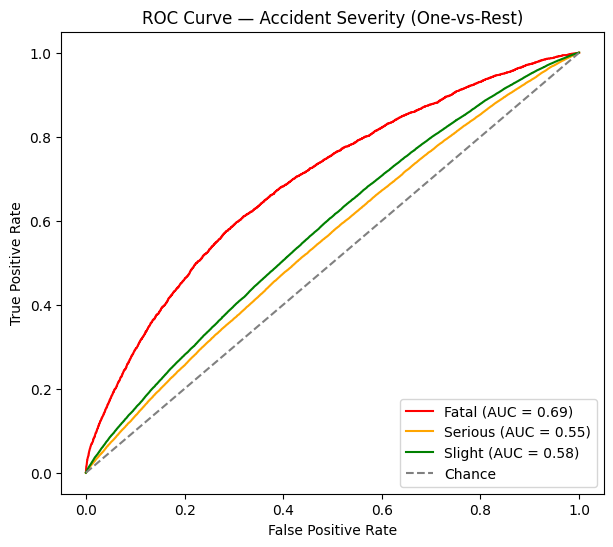

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

# ---- 1. Get out-of-fold predicted probabilities using the same pipeline/CV ----
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

y_proba = cross_val_predict(
    pipeline, X, y, cv=cv, method='predict_proba', n_jobs=-1
)

# ---- 2. Binarize the true labels for one-vs-rest ROC ----
classes = pipeline.classes_ if hasattr(pipeline, 'classes_') else sorted(y.unique())
# safer: fit once to get class order, or just use sorted unique labels matching y_proba columns
classes = sorted(y.unique())  # confirm this order matches y_proba column order
y_bin = label_binarize(y, classes=classes)

# ---- 3. Compute ROC curve and AUC for each class ----
fpr, tpr, roc_auc = {}, {}, {}
for i, cls in enumerate(classes):
    fpr[cls], tpr[cls], _ = roc_curve(y_bin[:, i], y_proba[:, i])
    roc_auc[cls] = auc(fpr[cls], tpr[cls])

# ---- 4. Macro and weighted AUC (single-number summaries) ----
macro_auc = roc_auc_score(y_bin, y_proba, average='macro', multi_class='ovr')
weighted_auc = roc_auc_score(y_bin, y_proba, average='weighted', multi_class='ovr')
print(f"Macro AUC   : {macro_auc:.3f}")
print(f"Weighted AUC: {weighted_auc:.3f}")
for cls in classes:
    print(f"{cls} AUC: {roc_auc[cls]:.3f}")

# ---- 5. Plot ----
plt.figure(figsize=(7, 6))
colors = {'Fatal': 'red', 'Serious': 'orange', 'Slight': 'green'}
for cls in classes:
    plt.plot(fpr[cls], tpr[cls], label=f'{cls} (AUC = {roc_auc[cls]:.2f})',
              color=colors.get(cls, None))

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Accident Severity (One-vs-Rest)')
plt.legend(loc='lower right')

In [ ]:
from google.colab import files
files.download('severity_rf_model.pkl')

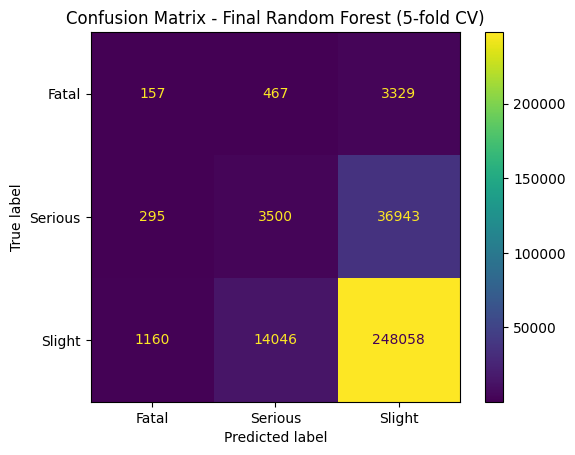

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay
y_pred_cv = cross_val_predict(pipeline, X, y, cv=cv, n_jobs=-1)
ConfusionMatrixDisplay.from_predictions(y, y_pred_cv, labels=["Fatal","Serious","Slight"], values_format="d")
plt.title("Confusion Matrix - Final Random Forest (5-fold CV)")
plt.show()